<a href="https://colab.research.google.com/github/musanyaks/Fraud-Detection-In-Insurance/blob/main/S6E11_Advanced_Fraud_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
base = '/content/drive/MyDrive'
print(os.path.exists(base))
print([d for d in os.listdir(base) if 'fraud' in d.lower() or 'credit' in d.lower()])

True
['Predicting Credit Card Fraud']


In [ ]:
import glob, zipfile, os
matches = glob.glob('/content/drive/**/playground-series-s6e11*.zip', recursive=True)
print(matches)

zip_path = matches[0]
extract_path = '/content/data'
os.makedirs(extract_path, exist_ok=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(extract_path)
print(os.listdir(extract_path))

['/content/drive/MyDrive/Predicting Credit Card Fraud/Predicting Credit Card Frau/playground-series-s6e11.zip']
['test.csv', 'train.csv', 'sample_submission.csv']


In [ ]:

import pandas as pd
import numpy as np

train = pd.read_csv('/content/data/train.csv')
test = pd.read_csv('/content/data/test.csv')

print("TRAIN DATA:", train.shape)
print("TEST DATA:", test.shape)

display(train.head())


TRAIN DATA: (699960, 26)
TEST DATA: (299984, 25)


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [ ]:

print("DATA TYPES")
display(train.dtypes)

print("\nMISSING VALUES")
display(train.isnull().sum().sort_values(ascending=False).head(20))

print("\nFRAUD DISTRIBUTION")
display(train['is_fraud'].value_counts())

print("\nFRAUD PROPORTIONS")
display(train['is_fraud'].value_counts(normalize=True) * 100)

print("\nDESCRIPTIVE STATISTICS")
display(train.describe(include='all').T)


DATA TYPES


,0
id,int64
amount_usd,float64
hours_since_last_txn,float64
txn_count_last_24h,int64
distance_from_home_km,float64
card_age_months,int64
customer_age,int64
account_balance_usd,float64
cvv_retry_count,int64
velocity_score,float64



MISSING VALUES


,0
id,0
amount_usd,0
hours_since_last_txn,0
txn_count_last_24h,0
distance_from_home_km,0
card_age_months,0
customer_age,0
account_balance_usd,0
cvv_retry_count,0
velocity_score,0



FRAUD DISTRIBUTION


,count
is_fraud,
0.0,688271
1.0,11689



FRAUD PROPORTIONS


,proportion
is_fraud,
0.0,98.330047
1.0,1.669953



DESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,699960.0,NaN,NaN,NaN,349979.5,202061.191548,0.0,174989.75,349979.5,524969.25,699959.0
amount_usd,699960.0,NaN,NaN,NaN,79.893068,205.173538,1.0,15.81,27.25,43.11,6872.69
hours_since_last_txn,699960.0,NaN,NaN,NaN,6.633734,6.290133,0.01,2.11,4.73,9.19,51.98
txn_count_last_24h,699960.0,NaN,NaN,NaN,2.984092,1.498998,0.0,2.0,3.0,4.0,11.0
distance_from_home_km,699960.0,NaN,NaN,NaN,13.587575,11.617325,0.0,4.43,10.22,19.75,57.93
card_age_months,699960.0,NaN,NaN,NaN,46.862982,5.57919,25.0,43.0,47.0,51.0,73.0
customer_age,699960.0,NaN,NaN,NaN,51.430286,17.89915,18.0,38.0,52.0,66.0,81.0
account_balance_usd,699960.0,NaN,NaN,NaN,2064.99807,3400.132922,58.25,834.12,1382.74,2517.02,99701.39
cvv_retry_count,699960.0,NaN,NaN,NaN,0.085472,0.289524,0.0,0.0,0.0,0.0,3.0
velocity_score,699960.0,NaN,NaN,NaN,18.929445,10.864385,0.0,11.4,18.6,26.0,72.9


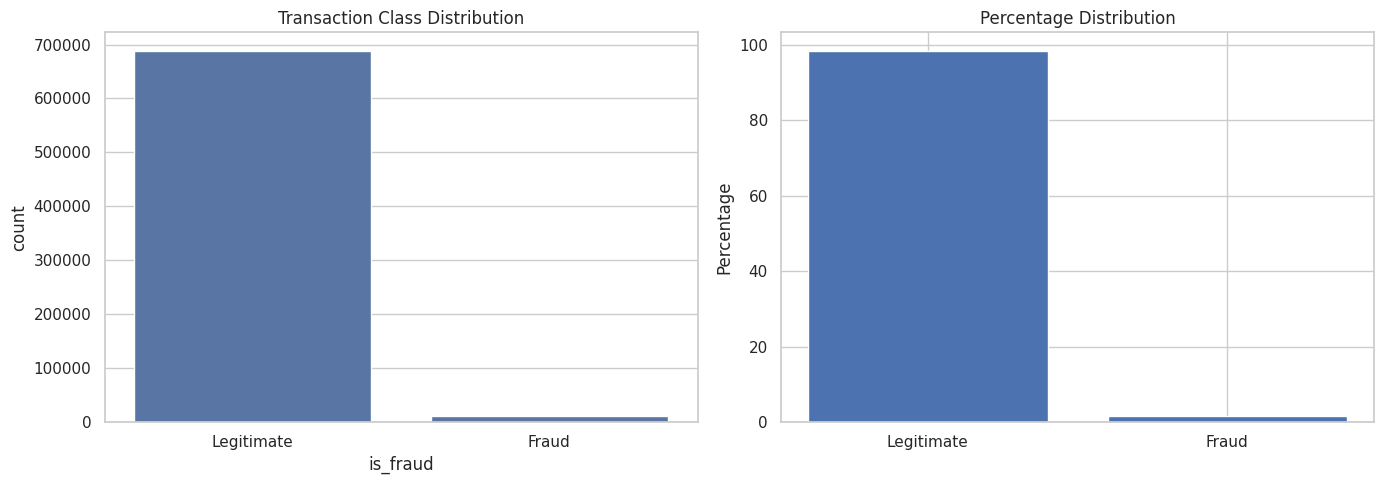

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

train['is_fraud'] = train['is_fraud'].astype('int8')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=train, x='is_fraud', ax=axes[0])
axes[0].set_title('Transaction Class Distribution')
axes[0].set_xticks([0, 1], ['Legitimate', 'Fraud'])

fraud_pct = train['is_fraud'].value_counts(normalize=True) * 100
axes[1].bar(['Legitimate', 'Fraud'], fraud_pct.sort_index())
axes[1].set_title('Percentage Distribution')
axes[1].set_ylabel('Percentage')

plt.tight_layout()
plt.show()


In [ ]:

categorical_cols = [
    'merchant_category',
    'card_type',
    'auth_method',
    'channel',
    'device_type'
]

for col in categorical_cols:
    summary = (
        train.groupby(col, observed=True)['is_fraud']
        .agg(['count', 'sum', 'mean'])
        .sort_values('mean', ascending=False)
    )

    summary['fraud_rate_pct'] = summary['mean'] * 100

    print(f'\nFRAUD ANALYSIS: {col}')
    display(summary[['count', 'sum', 'fraud_rate_pct']])



FRAUD ANALYSIS: merchant_category


,count,sum,fraud_rate_pct
merchant_category,,,
Gift Cards,9456,690,7.296954
Crypto Exchange,5285,345,6.527909
Gaming,23784,1311,5.512109
Electronics,48693,1501,3.082579
Streaming,47196,1061,2.248072
Travel,28715,534,1.859655
Utilities,42027,581,1.382445
Healthcare,35889,462,1.287303
Fuel,59880,741,1.237475



FRAUD ANALYSIS: card_type


,count,sum,fraud_rate_pct
card_type,,,
Amex,45797,871,1.901871
Visa,345001,5860,1.698546
RuPay,37070,623,1.680604
Mastercard,254857,4084,1.602467
Discover,17235,251,1.456339



FRAUD ANALYSIS: auth_method


,count,sum,fraud_rate_pct
auth_method,,,
No Authentication,67060,4322,6.444975
3D Secure,210036,3098,1.474985
OTP,175178,2464,1.406569
PIN,154020,1337,0.868069
Biometric,93666,468,0.499648



FRAUD ANALYSIS: channel


,count,sum,fraud_rate_pct
channel,,,
Online,273939,4773,1.742359
POS,206465,3428,1.660330
In-App,83716,1367,1.632902
ATM,30220,480,1.588352
Contactless,105620,1641,1.553683



FRAUD ANALYSIS: device_type


,count,sum,fraud_rate_pct
device_type,,,
POS Terminal,113237,1958,1.729117
iPhone,164691,2836,1.722013
Mac,33973,581,1.710182
Tablet,27688,471,1.701098
Smart Watch,21106,359,1.700938
ATM Machine,20877,354,1.695646
Windows PC,80934,1306,1.613661
Android Phone,237454,3824,1.610417


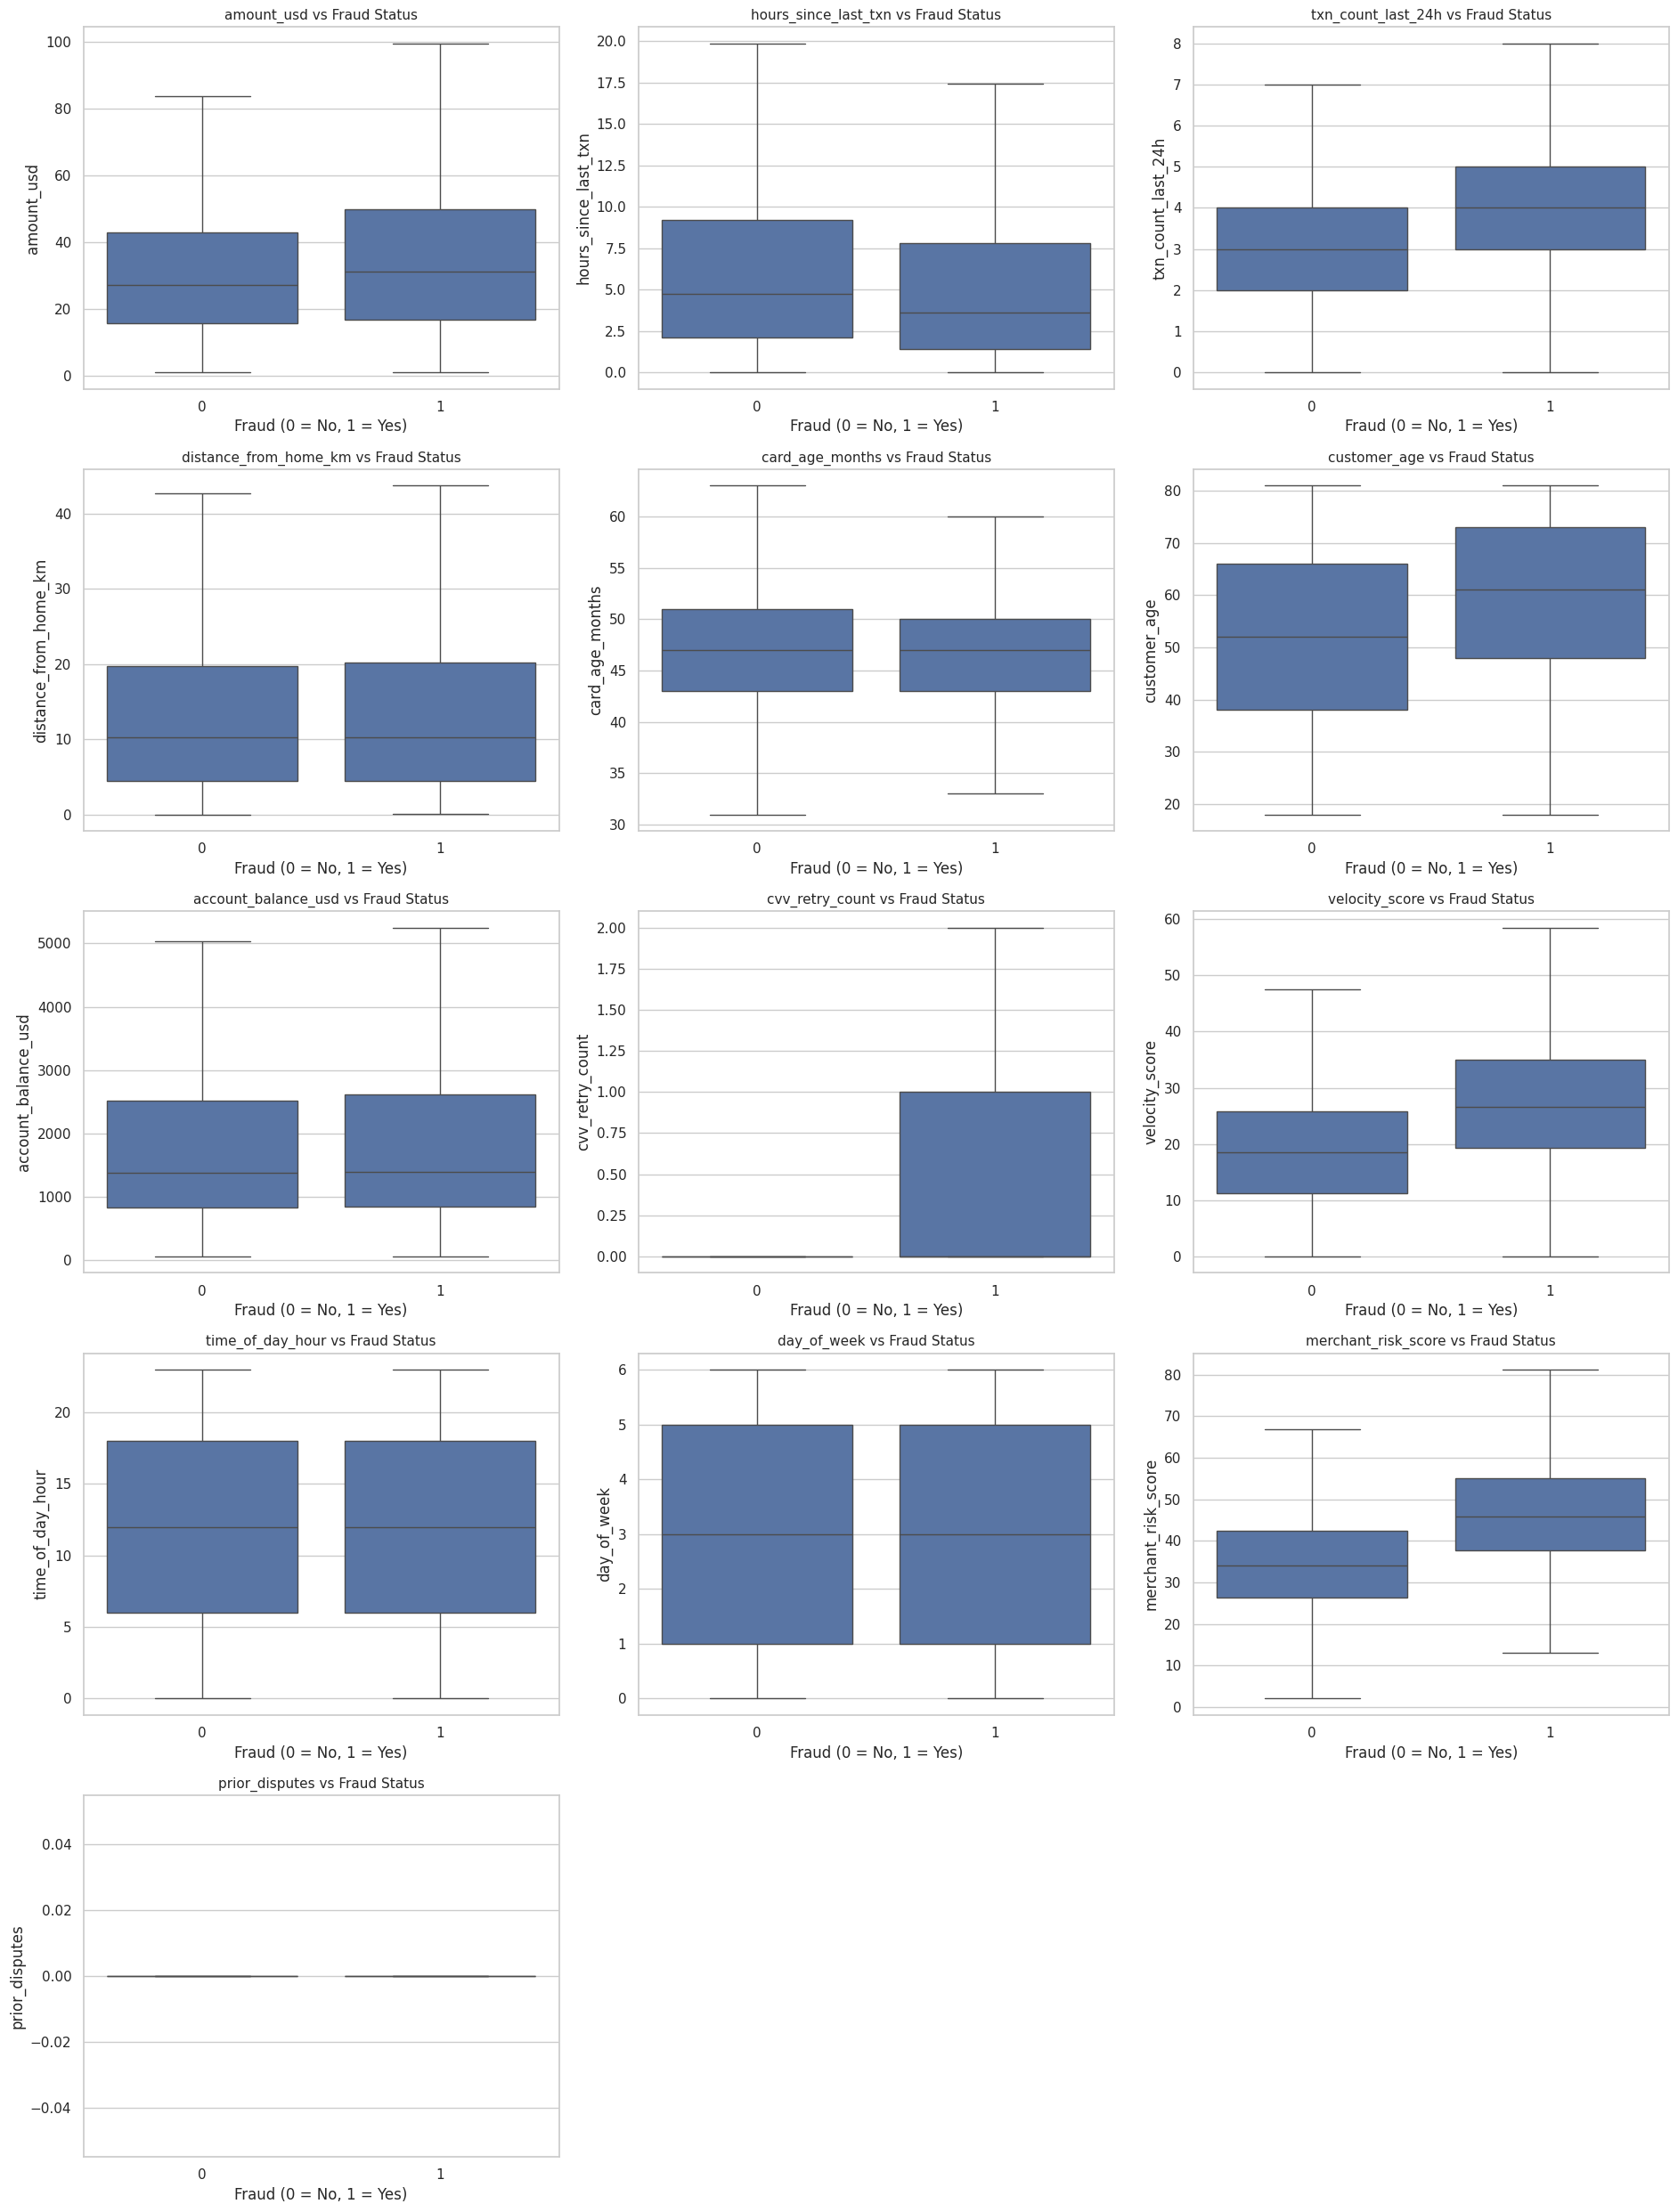

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import math

numeric_cols = [
    'amount_usd',
    'hours_since_last_txn',
    'txn_count_last_24h',
    'distance_from_home_km',
    'card_age_months',
    'customer_age',
    'account_balance_usd',
    'cvv_retry_count',
    'velocity_score',
    'time_of_day_hour',
    'day_of_week',
    'merchant_risk_score',
    'prior_disputes'
]

# Automatically calculate the required subplot rows
n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(19, 5 * n_rows)
)

axes = axes.flatten()

for i, col in enumerate(numeric_cols):

    sns.boxplot(
        data=train,
        x='is_fraud',
        y=col,
        ax=axes[i],
        showfliers=False
    )

    axes[i].set_title(
        f'{col} vs Fraud Status',
        fontsize=11
    )

    axes[i].set_xlabel('Fraud (0 = No, 1 = Yes)')

# Remove unused subplot spaces
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


In [ ]:

boolean_cols = [
    'is_foreign_transaction',
    'is_new_merchant',
    'used_vpn',
    'ip_country_mismatch',
    'billing_shipping_mismatch',
    'is_ai_generated_scam_attempt'
]

for col in boolean_cols:
    print(f'\n{col}')
    display(
        train.groupby(col, observed=True)['is_fraud']
        .agg(['count', 'mean'])
        .rename(columns={'mean': 'fraud_probability'})
    )



is_foreign_transaction


,count,fraud_probability
is_foreign_transaction,,
False,687862,0.014782
True,12098,0.125723



is_new_merchant


,count,fraud_probability
is_new_merchant,,
False,593240,0.011188
True,106720,0.047339



used_vpn


,count,fraud_probability
used_vpn,,
False,676295,0.014992
True,23665,0.065498


... (2 outputs left out)


billing_shipping_mismatch


,count,fraud_probability
billing_shipping_mismatch,,
False,690906,0.015216
True,9054,0.129887



is_ai_generated_scam_attempt


,count,fraud_probability
is_ai_generated_scam_attempt,,
False,697661,0.016253
True,2299,0.152240


,count,mean,fraud_rate_pct
id_bucket,,,
"(-0.001, 34997.95]",34998,0.016887,1.688668
"(34997.95, 69995.9]",34998,0.016515,1.651523
"(69995.9, 104993.85]",34998,0.015858,1.585805
"(104993.85, 139991.8]",34998,0.015887,1.588662
"(139991.8, 174989.75]",34998,0.016087,1.608663
"(174989.75, 209987.7]",34998,0.018144,1.814389
"(209987.7, 244985.65]",34998,0.016772,1.677239
"(244985.65, 279983.6]",34998,0.017915,1.791531
"(279983.6, 314981.55]",34998,0.017087,1.708669


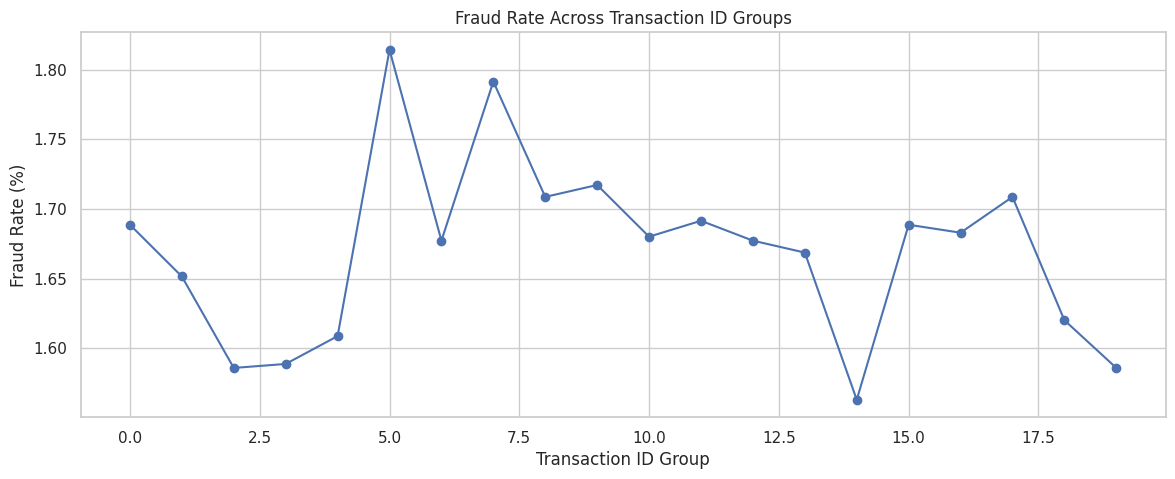

In [ ]:

train['id_bucket'] = pd.qcut(
    train['id'],
    q=20,
    duplicates='drop'
)

id_analysis = train.groupby(
    'id_bucket',
    observed=True
)['is_fraud'].agg(['count', 'mean'])

id_analysis['fraud_rate_pct'] = id_analysis['mean'] * 100

display(id_analysis)

plt.figure(figsize=(14, 5))
plt.plot(
    range(len(id_analysis)),
    id_analysis['fraud_rate_pct'],
    marker='o'
)
plt.title('Fraud Rate Across Transaction ID Groups')
plt.xlabel('Transaction ID Group')
plt.ylabel('Fraud Rate (%)')
plt.show()

train.drop(columns='id_bucket', inplace=True)


In [ ]:

from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import numpy as np

TARGET = 'is_fraud'
task_type='GPU'

X = train.drop(columns=[TARGET])
y = train[TARGET].astype(int)

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

oof_predictions = np.zeros(len(X))
fold_scores = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X, y), 1
):
    print(f'\nTraining fold {fold}')

    X_train = X.iloc[train_idx]
    X_valid = X.iloc[valid_idx]

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    model = CatBoostClassifier(
        iterations=1600,
        depth=7,
        learning_rate=0.04,
        loss_function='Logloss',
        eval_metric='AUC',
        random_seed=42 + fold,
        verbose=200,
        early_stopping_rounds=150,
        thread_count=-1
    )

    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features,
        eval_set=(X_valid, y_valid)
    )

    predictions = model.predict_proba(X_valid)[:, 1]

    oof_predictions[valid_idx] = predictions

    auc = roc_auc_score(y_valid, predictions)
    fold_scores.append(auc)

    print(f'Fold {fold} ROC-AUC: {auc:.6f}')

print('\nFINAL VALIDATION RESULTS')
print('Fold scores:', fold_scores)
print('Mean ROC-AUC:', np.mean(fold_scores))
print('Standard deviation:', np.std(fold_scores))

np.save('/content/catboost_oof.npy', oof_predictions)



Training fold 1
0:	test: 0.6466468	best: 0.6466468 (0)	total: 837ms	remaining: 22m 18s
200:	test: 0.9408437	best: 0.9408448 (199)	total: 2m 47s	remaining: 19m 25s
400:	test: 0.9427177	best: 0.9427177 (400)	total: 5m 26s	remaining: 16m 15s
600:	test: 0.9435103	best: 0.9435330 (584)	total: 8m 9s	remaining: 13m 33s
800:	test: 0.9440541	best: 0.9440612 (794)	total: 10m 54s	remaining: 10m 52s
1000:	test: 0.9441750	best: 0.9441750 (1000)	total: 13m 36s	remaining: 8m 8s
1200:	test: 0.9443491	best: 0.9443491 (1200)	total: 16m 20s	remaining: 5m 25s
1400:	test: 0.9443750	best: 0.9443974 (1332)	total: 19m 3s	remaining: 2m 42s
1599:	test: 0.9444049	best: 0.9444240 (1468)	total: 21m 44s	remaining: 0us

bestTest = 0.944423989
bestIteration = 1468

Shrink model to first 1469 iterations.
Fold 1 ROC-AUC: 0.944424

Training fold 2
0:	test: 0.8277549	best: 0.8277549 (0)	total: 816ms	remaining: 21m 44s
200:	test: 0.9450211	best: 0.9450211 (200)	total: 2m 48s	remaining: 19m 33s
400:	test: 0.9470596	best: 

In [ ]:

!pip install -q catboost


In [ ]:

import numpy as np
import pandas as pd

def create_features(df):

    df = df.copy()

    # 1. Financial behaviour
    df['amount_to_balance_ratio'] = (
        df['amount_usd'] / (df['account_balance_usd'] + 1)
    )

    df['amount_to_balance_share'] = (
        df['amount_usd'] /
        (df['amount_usd'] + df['account_balance_usd'] + 1)
    )

    df['log_amount'] = np.log1p(df['amount_usd'].clip(lower=0))
    df['log_account_balance'] = np.log1p(
        df['account_balance_usd'].clip(lower=0)
    )

    # 2. Transaction behaviour
    df['transaction_intensity'] = (
        df['txn_count_last_24h'] /
        (df['hours_since_last_txn'] + 1)
    )

    df['cvv_retry_intensity'] = (
        df['cvv_retry_count'] /
        (df['txn_count_last_24h'] + 1)
    )

    df['log_transaction_count'] = np.log1p(
        df['txn_count_last_24h']
    )

    # 3. Distance and transaction risk
    df['log_distance'] = np.log1p(
        df['distance_from_home_km'].clip(lower=0)
    )

    df['merchant_dispute_interaction'] = (
        df['merchant_risk_score'] *
        df['prior_disputes']
    )

    df['amount_merchant_risk'] = (
        df['amount_usd'] *
        df['merchant_risk_score']
    )

    # 4. Fraud-related interactions
    df['foreign_vpn_interaction'] = (
        df['is_foreign_transaction'].astype(int) *
        df['used_vpn'].astype(int)
    )

    df['country_foreign_interaction'] = (
        df['ip_country_mismatch'].astype(int) *
        df['is_foreign_transaction'].astype(int)
    )

    df['new_merchant_risk'] = (
        df['is_new_merchant'].astype(int) *
        df['merchant_risk_score']
    )

    df['billing_ip_mismatch'] = (
        df['billing_shipping_mismatch'].astype(int) *
        df['ip_country_mismatch'].astype(int)
    )

    df['scam_vpn_interaction'] = (
        df['is_ai_generated_scam_attempt'].astype(int) *
        df['used_vpn'].astype(int)
    )

    # 5. Cyclical time features
    df['hour_sin'] = np.sin(
        2 * np.pi * df['time_of_day_hour'] / 24
    )

    df['hour_cos'] = np.cos(
        2 * np.pi * df['time_of_day_hour'] / 24
    )

    df['day_sin'] = np.sin(
        2 * np.pi * df['day_of_week'] / 7
    )

    df['day_cos'] = np.cos(
        2 * np.pi * df['day_of_week'] / 7
    )

    return df


# Apply identical feature engineering to training and test data
train_fe = create_features(train)
test_fe = create_features(test)

print("Original training shape:", train.shape)
print("Engineered training shape:", train_fe.shape)
print("Engineered test shape:", test_fe.shape)

print("\nNew features created successfully.")


Original training shape: (699960, 26)
Engineered training shape: (699960, 45)
Engineered test shape: (299984, 44)

New features created successfully.


In [ ]:

TARGET = 'is_fraud'

X = train_fe.drop(columns=[TARGET])
y = train_fe[TARGET].astype(int)

X_test = test_fe.copy()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Training features:", X.shape)
print("Test features:", X_test.shape)
print("Categorical features:", categorical_features)


Training features: (699960, 44)
Test features: (299984, 44)
Categorical features: ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']


In [ ]:
!nvidia-smi

Thu Nov 19 15:11:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:

from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import numpy as np

TARGET = 'is_fraud'

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

oof_predictions = np.zeros(len(X))
fold_scores = []
best_iterations = []

for fold, (train_idx, valid_idx) in enumerate(cv.split(X, y), 1):

    print(f'\nTraining fold {fold}')

    X_train = X.iloc[train_idx]
    X_valid = X.iloc[valid_idx]

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    model = CatBoostClassifier(
        iterations=2000,
        depth=7,
        learning_rate=0.04,
        loss_function='Logloss',
        eval_metric='AUC',
        random_seed=42 + fold,
        verbose=200,
        early_stopping_rounds=150,
        task_type='GPU',
        devices='0',
        auto_class_weights=None
    )

    model.fit(
        X_train,
        y_train,
        cat_features=categorical_features,
        eval_set=(X_valid, y_valid)
    )

    predictions = model.predict_proba(X_valid)[:, 1]

    oof_predictions[valid_idx] = predictions

    auc = roc_auc_score(y_valid, predictions)

    fold_scores.append(auc)
    best_iterations.append(model.best_iteration_)

    print(f'Fold {fold} ROC-AUC: {auc:.6f}')
    print(f'Best iteration: {model.best_iteration_}')

print('\nFINAL GPU VALIDATION RESULTS')
print('Fold scores:', fold_scores)
print('Mean ROC-AUC:', np.mean(fold_scores))
print('Standard deviation:', np.std(fold_scores))

np.save('/content/catboost_oof_engineered.npy', oof_predictions)
np.save('/content/catboost_best_iterations_engineered.npy', best_iterations)



Training fold 1


Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.8440252	best: 0.8440252 (0)	total: 83.6ms	remaining: 2m 47s
200:	test: 0.9404232	best: 0.9404232 (200)	total: 12.3s	remaining: 1m 50s
400:	test: 0.9417759	best: 0.9417761 (398)	total: 22.4s	remaining: 1m 29s
600:	test: 0.9423240	best: 0.9423273 (599)	total: 33.8s	remaining: 1m 18s
800:	test: 0.9427319	best: 0.9427319 (800)	total: 45.5s	remaining: 1m 8s
1000:	test: 0.9428107	best: 0.9428164 (965)	total: 57.2s	remaining: 57s
1200:	test: 0.9428748	best: 0.9428861 (1196)	total: 1m 9s	remaining: 46.4s
1400:	test: 0.9428154	best: 0.9428996 (1292)	total: 1m 19s	remaining: 34.2s
bestTest = 0.9428996146
bestIteration = 1292
Shrink model to first 1293 iterations.
Fold 1 ROC-AUC: 0.942900
Best iteration: 1292

Training fold 2


Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.8450432	best: 0.8450432 (0)	total: 73.1ms	remaining: 2m 26s
200:	test: 0.9449174	best: 0.9449174 (200)	total: 11.7s	remaining: 1m 44s
400:	test: 0.9462175	best: 0.9462177 (398)	total: 23.4s	remaining: 1m 33s
600:	test: 0.9466558	best: 0.9466593 (592)	total: 33.7s	remaining: 1m 18s
800:	test: 0.9468595	best: 0.9468666 (793)	total: 45.6s	remaining: 1m 8s
1000:	test: 0.9469358	best: 0.9469568 (931)	total: 57.4s	remaining: 57.2s
1200:	test: 0.9470276	best: 0.9470432 (1174)	total: 1m 9s	remaining: 46s
1400:	test: 0.9470645	best: 0.9470696 (1355)	total: 1m 20s	remaining: 34.6s
bestTest = 0.9471427798
bestIteration = 1448
Shrink model to first 1449 iterations.
Fold 2 ROC-AUC: 0.947143
Best iteration: 1448

Training fold 3


Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.7718639	best: 0.7718639 (0)	total: 73.4ms	remaining: 2m 26s
200:	test: 0.9383063	best: 0.9383063 (200)	total: 12s	remaining: 1m 47s
400:	test: 0.9398035	best: 0.9398089 (395)	total: 22.4s	remaining: 1m 29s
600:	test: 0.9403777	best: 0.9403808 (595)	total: 34.3s	remaining: 1m 19s
800:	test: 0.9407691	best: 0.9407705 (762)	total: 46.3s	remaining: 1m 9s
1000:	test: 0.9409662	best: 0.9409765 (995)	total: 58.6s	remaining: 58.4s
1200:	test: 0.9410820	best: 0.9411030 (1118)	total: 1m 10s	remaining: 46.7s
bestTest = 0.9411030412
bestIteration = 1118
Shrink model to first 1119 iterations.
Fold 3 ROC-AUC: 0.941103
Best iteration: 1118

FINAL GPU VALIDATION RESULTS
Fold scores: [np.float64(0.9428996555501981), np.float64(0.9471427285606107), np.float64(0.9411030694601116)]
Mean ROC-AUC: 0.9437151511903067
Standard deviation: 0.0025322118614415057


In [ ]:
!pip install -q lightgbm

In [ ]:

import lightgbm as lgb
import numpy as np

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

TARGET = 'is_fraud'

X_lgb = train.drop(columns=[TARGET]).copy()
y_lgb = train[TARGET].astype(int)

X_test_lgb = test.copy()

# Encode categorical variables consistently
categorical_cols = X_lgb.select_dtypes(
    include=['object']
).columns.tolist()

for col in categorical_cols:
    X_lgb[col] = X_lgb[col].astype('category')

    X_test_lgb[col] = pd.Categorical(
        X_test_lgb[col],
        categories=X_lgb[col].cat.categories
    )

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

lgb_oof = np.zeros(len(X_lgb))
lgb_test = np.zeros(len(X_test_lgb))

lgb_scores = []

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X_lgb, y_lgb), 1
):

    print(f'\nLightGBM Fold {fold}')

    model = lgb.LGBMClassifier(
        objective='binary',
        n_estimators=3000,
        learning_rate=0.03,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42 + fold,
        n_jobs=-1,
        verbosity=-1,
        device_type='cpu'
    )

    model.fit(
        X_lgb.iloc[train_idx],
        y_lgb.iloc[train_idx],
        categorical_feature=categorical_cols,
        eval_set=[(
            X_lgb.iloc[valid_idx],
            y_lgb.iloc[valid_idx]
        )],
        eval_metric='auc',
        callbacks=[
            lgb.early_stopping(150),
            lgb.log_evaluation(200)
        ]
    )

    valid_pred = model.predict_proba(
        X_lgb.iloc[valid_idx]
    )[:, 1]

    lgb_oof[valid_idx] = valid_pred

    test_pred = model.predict_proba(
        X_test_lgb,
        num_iteration=model.best_iteration_
    )[:, 1]

    lgb_test += test_pred / 3

    auc = roc_auc_score(
        y_lgb.iloc[valid_idx],
        valid_pred
    )

    lgb_scores.append(auc)

    print(f'Fold {fold} ROC-AUC: {auc:.6f}')

print('\nLIGHTGBM RESULTS')
print('Fold scores:', lgb_scores)
print('Mean ROC-AUC:', np.mean(lgb_scores))

np.save('/content/lightgbm_oof.npy', lgb_oof)
np.save('/content/lightgbm_test.npy', lgb_test)



LightGBM Fold 1
Training until validation scores don't improve for 150 rounds
[200]	valid_0's auc: 0.943018	valid_0's binary_logloss: 0.0473704
[400]	valid_0's auc: 0.944382	valid_0's binary_logloss: 0.0468222
[600]	valid_0's auc: 0.944701	valid_0's binary_logloss: 0.0467101
[800]	valid_0's auc: 0.944844	valid_0's binary_logloss: 0.0466788
Early stopping, best iteration is:
[812]	valid_0's auc: 0.944856	valid_0's binary_logloss: 0.0466707
Fold 1 ROC-AUC: 0.944856

LightGBM Fold 2
Training until validation scores don't improve for 150 rounds
[200]	valid_0's auc: 0.9481	valid_0's binary_logloss: 0.0459651
[400]	valid_0's auc: 0.948818	valid_0's binary_logloss: 0.0454482
[600]	valid_0's auc: 0.948899	valid_0's binary_logloss: 0.0453872
Early stopping, best iteration is:
[635]	valid_0's auc: 0.948943	valid_0's binary_logloss: 0.0453738
Fold 2 ROC-AUC: 0.948943

LightGBM Fold 3
Training until validation scores don't improve for 150 rounds
[200]	valid_0's auc: 0.941451	valid_0's binary_logl

In [ ]:

import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

# Load out-of-fold predictions
cat_oof = np.load('/content/catboost_oof.npy')
lgb_oof = np.load('/content/lightgbm_oof.npy')

# Check alignment
assert len(cat_oof) == len(y)
assert len(lgb_oof) == len(y)

# Same folds used in model training
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Test different blending weights
results = []

for cat_weight in np.arange(0, 1.01, 0.05):

    lgb_weight = 1 - cat_weight

    blended = (
        cat_weight * cat_oof +
        lgb_weight * lgb_oof
    )

    overall_auc = roc_auc_score(y, blended)

    fold_aucs = []

    for _, valid_idx in cv.split(np.zeros(len(y)), y):
        fold_auc = roc_auc_score(
            y.iloc[valid_idx],
            blended[valid_idx]
        )
        fold_aucs.append(fold_auc)

    results.append({
        'CatBoost_weight': round(cat_weight, 2),
        'LightGBM_weight': round(lgb_weight, 2),
        'Overall_AUC': overall_auc,
        'Fold1_AUC': fold_aucs[0],
        'Fold2_AUC': fold_aucs[1],
        'Fold3_AUC': fold_aucs[2]
    })

results = sorted(
    results,
    key=lambda x: x['Overall_AUC'],
    reverse=True
)

print("TOP 10 ENSEMBLE COMBINATIONS")

for result in results[:10]:
    print(result)

# Save the best OOF blend for further analysis
best = results[0]

best_blend = (
    best['CatBoost_weight'] * cat_oof +
    best['LightGBM_weight'] * lgb_oof
)

np.save('/content/best_ensemble_oof.npy', best_blend)

print("\nBest ensemble ROC-AUC:", best['Overall_AUC'])
print("Best weights:", best)


TOP 10 ENSEMBLE COMBINATIONS
{'CatBoost_weight': np.float64(0.45), 'LightGBM_weight': np.float64(0.55), 'Overall_AUC': np.float64(0.9459918025435907), 'Fold1_AUC': np.float64(0.9454299924832735), 'Fold2_AUC': np.float64(0.9494448524636574), 'Fold3_AUC': np.float64(0.9432653302768408)}
{'CatBoost_weight': np.float64(0.4), 'LightGBM_weight': np.float64(0.6), 'Overall_AUC': np.float64(0.9459891914213397), 'Fold1_AUC': np.float64(0.9454332324515797), 'Fold2_AUC': np.float64(0.9494446689847894), 'Fold3_AUC': np.float64(0.9432580701493205)}
{'CatBoost_weight': np.float64(0.5), 'LightGBM_weight': np.float64(0.5), 'Overall_AUC': np.float64(0.9459826066252067), 'Fold1_AUC': np.float64(0.9454147413617433), 'Fold2_AUC': np.float64(0.9494356371256262), 'Fold3_AUC': np.float64(0.943259580112678)}
{'CatBoost_weight': np.float64(0.35), 'LightGBM_weight': np.float64(0.65), 'Overall_AUC': np.float64(0.9459730097223705), 'Fold1_AUC': np.float64(0.9454217191526019), 'Fold2_AUC': np.float64(0.949432775302

In [ ]:

from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
import numpy as np

TARGET = 'is_fraud'

# Restore original, non-engineered features
X_raw = train.drop(columns=[TARGET]).copy()
y_raw = train[TARGET].astype(int)

X_test_raw = test.copy()

cat_features = X_raw.select_dtypes(
    include=['object']
).columns.tolist()

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cat_test_predictions = np.zeros(len(test))

for fold, (train_idx, valid_idx) in enumerate(
    cv.split(X_raw, y_raw), 1
):

    print(f'\nFinal CatBoost training fold {fold}')

    model = CatBoostClassifier(
        iterations=1600,
        depth=7,
        learning_rate=0.04,
        loss_function='Logloss',
        eval_metric='AUC',
        random_seed=42 + fold,
        verbose=200,
        early_stopping_rounds=150,
        task_type='GPU',
        devices='0'
    )

    model.fit(
        X_raw.iloc[train_idx],
        y_raw.iloc[train_idx],
        cat_features=cat_features,
        eval_set=(
            X_raw.iloc[valid_idx],
            y_raw.iloc[valid_idx]
        )
    )

    cat_test_predictions += (
        model.predict_proba(X_test_raw)[:, 1] / 3
    )

np.save(
    '/content/catboost_test.npy',
    cat_test_predictions
)

print("\nCatBoost test predictions completed.")



Final CatBoost training fold 1


Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.8550269	best: 0.8550269 (0)	total: 110ms	remaining: 2m 56s
200:	test: 0.9406844	best: 0.9406844 (200)	total: 10.8s	remaining: 1m 15s
400:	test: 0.9422727	best: 0.9422727 (400)	total: 22.3s	remaining: 1m 6s
600:	test: 0.9427810	best: 0.9427810 (600)	total: 34s	remaining: 56.6s
800:	test: 0.9431301	best: 0.9431403 (792)	total: 45.7s	remaining: 45.6s
1000:	test: 0.9433432	best: 0.9433464 (999)	total: 58s	remaining: 34.7s
1200:	test: 0.9434019	best: 0.9434140 (1187)	total: 1m 8s	remaining: 22.9s
bestTest = 0.9434179068
bestIteration = 1220
Shrink model to first 1221 iterations.

Final CatBoost training fold 2


Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.8190605	best: 0.8190605 (0)	total: 104ms	remaining: 2m 45s
200:	test: 0.9452986	best: 0.9452986 (200)	total: 11.5s	remaining: 1m 19s
400:	test: 0.9467109	best: 0.9467109 (400)	total: 22.8s	remaining: 1m 8s
600:	test: 0.9472235	best: 0.9472235 (600)	total: 34.5s	remaining: 57.3s
800:	test: 0.9474693	best: 0.9474716 (799)	total: 46.1s	remaining: 46s
1000:	test: 0.9474559	best: 0.9474987 (862)	total: 56.5s	remaining: 33.8s
bestTest = 0.9474986792
bestIteration = 862
Shrink model to first 863 iterations.

Final CatBoost training fold 3


Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.8467807	best: 0.8467807 (0)	total: 73.5ms	remaining: 1m 57s
200:	test: 0.9384482	best: 0.9384482 (200)	total: 11s	remaining: 1m 16s
400:	test: 0.9402305	best: 0.9402305 (400)	total: 21.7s	remaining: 1m 4s
600:	test: 0.9408751	best: 0.9408751 (600)	total: 33.2s	remaining: 55.2s
800:	test: 0.9412183	best: 0.9412183 (800)	total: 44.8s	remaining: 44.7s
1000:	test: 0.9413660	best: 0.9414110 (955)	total: 56.7s	remaining: 33.9s
1200:	test: 0.9414566	best: 0.9414582 (1142)	total: 1m 7s	remaining: 22.6s
1400:	test: 0.9414774	best: 0.9414989 (1349)	total: 1m 18s	remaining: 11.2s
bestTest = 0.9414989352
bestIteration = 1349
Shrink model to first 1350 iterations.

CatBoost test predictions completed.


In [ ]:

import numpy as np

cat_test = np.load('/content/catboost_test.npy')
lgb_test = np.load('/content/lightgbm_test.npy')

assert len(cat_test) == len(test)
assert len(lgb_test) == len(test)

final_predictions = (
    0.45 * cat_test +
    0.55 * lgb_test
)

print("Prediction count:", len(final_predictions))
print("Minimum probability:", final_predictions.min())
print("Maximum probability:", final_predictions.max())
print("Mean probability:", final_predictions.mean())

np.save(
    '/content/final_fraud_predictions.npy',
    final_predictions
)


Prediction count: 299984
Minimum probability: 5.40591560016823e-06
Maximum probability: 0.9957185990991808
Mean probability: 0.015528155259775796


In [ ]:

submission = sample_submission.copy()

submission[TARGET] = final_predictions

submission.to_csv(
    '/content/submission.csv',
    index=False
)

print(submission.head())
print("Submission shape:", submission.shape)


NameError: name 'sample_submission' is not defined

In [ ]:
import pandas as pd
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/Predicting Credit Card Fraud/playground-series-s6e11.zip"

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    print([f for f in z.namelist() if "sample_submission" in f.lower()])

['sample_submission.csv']


In [ ]:
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    sample_file = [
        f for f in z.namelist()
        if "sample_submission" in f.lower()
    ][0]

    sample_submission = pd.read_csv(z.open(sample_file))

print(sample_submission.head())
print(sample_submission.shape)

       id  is_fraud
0  699960    0.0167
1  699961    0.0167
2  699962    0.0167
3  699963    0.0167
4  699964    0.0167
(299984, 2)


In [ ]:
from google.colab import files
files.download('/content/submission.csv')

FileNotFoundError: Cannot find file: /content/submission.csv

In [ ]:
import pandas as pd
import numpy as np
import zipfile
import os
from google.colab import files

# 1. Locate your competition ZIP file
ZIP_PATH = "/content/drive/MyDrive/Predicting Credit Card Fraud/playground-series-s6e11.zip"

# 2. Check that your prediction file exists
PREDICTION_PATH = "/content/final_fraud_predictions.npy"

if not os.path.exists(PREDICTION_PATH):
    raise FileNotFoundError(
        "Your prediction file is missing. We need to regenerate the predictions."
    )

# 3. Load predictions
final_predictions = np.load(PREDICTION_PATH)

# 4. Load sample submission directly from ZIP
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    sample_file = next(
        f for f in z.namelist()
        if "sample_submission" in f.lower() and f.endswith(".csv")
    )
    sample_submission = pd.read_csv(z.open(sample_file))

# 5. Create submission
submission = sample_submission.copy()

assert len(submission) == len(final_predictions), "Prediction length mismatch!"

submission["is_fraud"] = final_predictions

# 6. Validate
assert submission["is_fraud"].notna().all()
assert submission["is_fraud"].between(0, 1).all()

# 7. Save
OUTPUT_PATH = "/content/submission.csv"
submission.to_csv(OUTPUT_PATH, index=False)

# 8. Confirm file exists
print("SUCCESS: Submission created!")
print("File exists:", os.path.exists(OUTPUT_PATH))
print("Shape:", submission.shape)
print(submission.head())

# 9. Download
files.download(OUTPUT_PATH)

SUCCESS: Submission created!
File exists: True
Shape: (299984, 2)
       id  is_fraud
0  699960  0.000226
1  699961  0.000130
2  699962  0.084224
3  699963  0.001155
4  699964  0.001447


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np
import pandas as pd
import os
import gc

from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

# ==========================================
# 1. PREPARE DATA
# ==========================================

TARGET = "is_fraud"

X = train.drop(columns=[TARGET]).copy()
y = train[TARGET].astype(int).copy()
X_test = test[X.columns].copy()

# Identify categorical columns
cat_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Ensure categorical values are consistent
for col in cat_features:
    X[col] = X[col].astype(str)
    X_test[col] = X_test[col].astype(str)

print("Training shape:", X.shape)
print("Test shape:", X_test.shape)
print("Categorical features:", cat_features)

# ==========================================
# 2. CHECK LIGHTGBM FILES
# ==========================================

assert os.path.exists("/content/lightgbm_oof.npy"), \
    "LightGBM OOF predictions are missing."

assert os.path.exists("/content/lightgbm_test.npy"), \
    "LightGBM test predictions are missing."

lgb_oof = np.load("/content/lightgbm_oof.npy")
lgb_test = np.load("/content/lightgbm_test.npy")

assert len(lgb_oof) == len(y)
assert len(lgb_test) == len(X_test)

# ==========================================
# 3. GPU CATBOOST CROSS-VALIDATION
# ==========================================

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cat_oof_gpu = np.zeros(len(X))
cat_test_gpu = np.zeros(len(X_test))

fold_scores = []
best_iterations = []

for fold, (train_idx, valid_idx) in enumerate(
    skf.split(X, y), 1
):

    print(f"\n========== GPU FOLD {fold} ==========")

    X_train = X.iloc[train_idx]
    X_valid = X.iloc[valid_idx]

    y_train = y.iloc[train_idx]
    y_valid = y.iloc[valid_idx]

    model = CatBoostClassifier(
        iterations=1600,
        depth=7,
        learning_rate=0.04,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=42 + fold,
        task_type="GPU",
        devices="0",
        verbose=200,
        early_stopping_rounds=150
    )

    model.fit(
        X_train,
        y_train,
        cat_features=cat_features,
        eval_set=(X_valid, y_valid),
        verbose=200,
        early_stopping_rounds=150
    )

    # Validation predictions
    valid_preds = model.predict_proba(X_valid)[:, 1]
    cat_oof_gpu[valid_idx] = valid_preds

    # Test predictions
    cat_test_gpu += (
        model.predict_proba(X_test)[:, 1] / 3
    )

    fold_auc = roc_auc_score(y_valid, valid_preds)
    fold_scores.append(fold_auc)

    best_iterations.append(model.best_iteration_)

    print(f"Fold {fold} AUC: {fold_auc:.8f}")
    print(f"Best iteration: {model.best_iteration_}")

    del model, X_train, X_valid
    del y_train, y_valid
    gc.collect()

# ==========================================
# 4. SAVE GPU PREDICTIONS
# ==========================================

np.save("/content/catboost_gpu_oof.npy", cat_oof_gpu)
np.save("/content/catboost_gpu_test.npy", cat_test_gpu)

print("\n========== CATBOOST GPU RESULTS ==========")

print("Fold AUC scores:", fold_scores)
print("Mean fold AUC:", np.mean(fold_scores))
print("Overall OOF AUC:", roc_auc_score(y, cat_oof_gpu))
print("Best iterations:", best_iterations)

# ==========================================
# 5. OPTIMIZE ENSEMBLE WEIGHTS
# ==========================================

weights = np.arange(0, 1.01, 0.01)

results = []

for w in weights:

    blended_oof = (
        w * cat_oof_gpu +
        (1 - w) * lgb_oof
    )

    auc = roc_auc_score(y, blended_oof)

    results.append((w, 1 - w, auc))

best_result = max(results, key=lambda x: x[2])

best_cat_weight = best_result[0]
best_lgb_weight = best_result[1]
best_auc = best_result[2]

print("\n========== BEST ENSEMBLE ==========")

print("CatBoost GPU weight:", best_cat_weight)
print("LightGBM weight:", best_lgb_weight)
print("Blended OOF AUC:", best_auc)

# ==========================================
# 6. GENERATE FINAL TEST PREDICTIONS
# ==========================================

final_predictions = (
    best_cat_weight * cat_test_gpu +
    best_lgb_weight * lgb_test
)

np.save(
    "/content/final_fraud_predictions_v2.npy",
    final_predictions
)

print("\n========== FINAL TEST PREDICTIONS ==========")

print("Prediction count:", len(final_predictions))
print("Minimum:", final_predictions.min())
print("Maximum:", final_predictions.max())
print("Mean:", final_predictions.mean())

print("\nGPU training and ensemble completed!")


Training shape: (699960, 25)
Test shape: (299984, 25)
Categorical features: ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']

========== GPU FOLD 1 ==========


Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.8550269	best: 0.8550269 (0)	total: 71.1ms	remaining: 1m 53s
200:	test: 0.9406844	best: 0.9406844 (200)	total: 11.7s	remaining: 1m 21s
400:	test: 0.9422727	best: 0.9422727 (400)	total: 23.3s	remaining: 1m 9s
600:	test: 0.9427349	best: 0.9427380 (565)	total: 35.4s	remaining: 58.8s
800:	test: 0.9430376	best: 0.9430379 (796)	total: 46.6s	remaining: 46.5s
1000:	test: 0.9432661	best: 0.9432696 (999)	total: 57.5s	remaining: 34.4s
1200:	test: 0.9433942	best: 0.9434028 (1197)	total: 1m 9s	remaining: 22.9s
bestTest = 0.9434028268
bestIteration = 1197
Shrink model to first 1198 iterations.
Fold 1 AUC: 0.94340274
Best iteration: 1197

========== GPU FOLD 2 ==========


Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.8190605	best: 0.8190605 (0)	total: 73.4ms	remaining: 1m 57s
200:	test: 0.9452986	best: 0.9452986 (200)	total: 11.7s	remaining: 1m 21s
400:	test: 0.9467109	best: 0.9467109 (400)	total: 23.3s	remaining: 1m 9s
600:	test: 0.9472235	best: 0.9472235 (600)	total: 34.8s	remaining: 57.8s
800:	test: 0.9474693	best: 0.9474716 (799)	total: 45.4s	remaining: 45.3s
1000:	test: 0.9474558	best: 0.9474987 (862)	total: 57.2s	remaining: 34.2s
bestTest = 0.9474986792
bestIteration = 862
Shrink model to first 863 iterations.
Fold 2 AUC: 0.94749875
Best iteration: 862

========== GPU FOLD 3 ==========


Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.8467807	best: 0.8467807 (0)	total: 72.8ms	remaining: 1m 56s
200:	test: 0.9384482	best: 0.9384482 (200)	total: 10.5s	remaining: 1m 13s
400:	test: 0.9402305	best: 0.9402305 (400)	total: 21.8s	remaining: 1m 5s
600:	test: 0.9408751	best: 0.9408751 (600)	total: 33.5s	remaining: 55.7s
800:	test: 0.9412182	best: 0.9412182 (800)	total: 45.4s	remaining: 45.3s
1000:	test: 0.9413607	best: 0.9414089 (957)	total: 57.3s	remaining: 34.3s
1200:	test: 0.9414308	best: 0.9414330 (1078)	total: 1m 8s	remaining: 22.7s
bestTest = 0.9414388835
bestIteration = 1242
Shrink model to first 1243 iterations.
Fold 3 AUC: 0.94143888
Best iteration: 1242

========== CATBOOST GPU RESULTS ==========
Fold AUC scores: [np.float64(0.943402740062677), np.float64(0.9474987491663796), np.float64(0.9414388785998308)]
Mean fold AUC: 0.9441134559429624
Overall OOF AUC: 0.9440356651511488
Best iterations: [1197, 862, 1242]

========== BEST ENSEMBLE ==========
CatBoost GPU weight: 0.27
LightGBM weight: 0.73
Blended OOF 

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from scipy.stats import rankdata

# Load all OOF predictions
cpu_oof = np.load("/content/catboost_oof.npy")
lgb_oof = np.load("/content/lightgbm_oof.npy")
gpu_oof = np.load("/content/catboost_gpu_oof.npy")

# Load all test predictions
cpu_test = np.load("/content/catboost_test.npy")
lgb_test = np.load("/content/lightgbm_test.npy")
gpu_test = np.load("/content/catboost_gpu_test.npy")

y = train["is_fraud"].astype(int).values

# Confirm matching dimensions
assert len(cpu_oof) == len(y)
assert len(lgb_oof) == len(y)
assert len(gpu_oof) == len(y)

assert len(cpu_test) == len(test)
assert len(lgb_test) == len(test)
assert len(gpu_test) == len(test)

# Baseline
baseline_auc = roc_auc_score(
    y, 0.45 * cpu_oof + 0.55 * lgb_oof
)

print("Existing ensemble OOF:", baseline_auc)

# Search three-model combinations
results = []

weights = np.arange(0, 1.001, 0.02)

for cpu_w in weights:
    for gpu_w in weights:

        lgb_w = 1 - cpu_w - gpu_w

        if lgb_w < -1e-9:
            continue

        blended = (
            cpu_w * cpu_oof +
            lgb_w * lgb_oof +
            gpu_w * gpu_oof
        )

        auc = roc_auc_score(y, blended)

        results.append({
            "CPU_CatBoost": cpu_w,
            "LightGBM": lgb_w,
            "GPU_CatBoost": gpu_w,
            "OOF_AUC": auc
        })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "OOF_AUC", ascending=False
).reset_index(drop=True)

print("\nTOP 10 PROBABILITY BLENDS")
print(results_df.head(10).to_string(index=False))

best = results_df.iloc[0]

print("\nBEST WEIGHTS")
print(best)

# ======================================
# RANK-BASED BLENDING
# ======================================

cpu_rank = rankdata(cpu_oof) / len(cpu_oof)
lgb_rank = rankdata(lgb_oof) / len(lgb_oof)
gpu_rank = rankdata(gpu_oof) / len(gpu_oof)

rank_results = []

for cpu_w in weights:
    for gpu_w in weights:

        lgb_w = 1 - cpu_w - gpu_w

        if lgb_w < -1e-9:
            continue

        blended_rank = (
            cpu_w * cpu_rank +
            lgb_w * lgb_rank +
            gpu_w * gpu_rank
        )

        auc = roc_auc_score(y, blended_rank)

        rank_results.append({
            "CPU_CatBoost": cpu_w,
            "LightGBM": lgb_w,
            "GPU_CatBoost": gpu_w,
            "OOF_AUC": auc
        })

rank_df = pd.DataFrame(rank_results)
rank_df = rank_df.sort_values(
    "OOF_AUC", ascending=False
).reset_index(drop=True)

print("\nTOP 10 RANK BLENDS")
print(rank_df.head(10).to_string(index=False))

# ======================================
# SAVE BEST PROBABILITY BLEND
# ======================================

cpu_w = float(best["CPU_CatBoost"])
lgb_w = float(best["LightGBM"])
gpu_w = float(best["GPU_CatBoost"])

best_test_predictions = (
    cpu_w * cpu_test +
    lgb_w * lgb_test +
    gpu_w * gpu_test
)

np.save(
    "/content/three_model_predictions.npy",
    best_test_predictions
)

print("\nThree-model predictions saved.")
print("Prediction mean:", best_test_predictions.mean())
print("Prediction range:",
      best_test_predictions.min(),
      best_test_predictions.max())

Existing ensemble OOF: 0.9459918025435907

TOP 10 PROBABILITY BLENDS
 CPU_CatBoost  LightGBM  GPU_CatBoost  OOF_AUC
         0.44      0.56          0.00 0.945992
         0.42      0.56          0.02 0.945992
         0.42      0.58          0.00 0.945992
         0.40      0.58          0.02 0.945992
         0.44      0.54          0.02 0.945991
         0.46      0.54          0.00 0.945991
         0.40      0.56          0.04 0.945990
         0.38      0.58          0.04 0.945989
         0.40      0.60          0.00 0.945989
         0.42      0.54          0.04 0.945989

BEST WEIGHTS
CPU_CatBoost    0.440000
LightGBM        0.560000
GPU_CatBoost    0.000000
OOF_AUC         0.945992
Name: 0, dtype: float64

TOP 10 RANK BLENDS
 CPU_CatBoost  LightGBM  GPU_CatBoost  OOF_AUC
         0.44      0.56          0.00 0.946000
         0.42      0.56          0.02 0.945999
         0.46      0.54          0.00 0.945999
         0.44      0.54          0.02 0.945999
         0.42      0.

In [ ]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

import torch
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

XGBoost version: 3.4.1
CUDA available: True
GPU: Tesla T4


In [ ]:
import numpy as np
import pandas as pd
import gc

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

TARGET = "is_fraud"

# Separate features and target
X_xgb_raw = train.drop(columns=[TARGET]).copy()
y_xgb = train[TARGET].astype(int).copy()

X_test_raw = test[X_xgb_raw.columns].copy()

# One-hot encode categorical variables
combined = pd.concat(
    [X_xgb_raw, X_test_raw],
    axis=0,
    ignore_index=True
)

combined = pd.get_dummies(
    combined,
    columns=combined.select_dtypes(
        include=["object", "category"]
    ).columns.tolist(),
    dtype=np.uint8
)

# Split back into training and test
X_xgb = combined.iloc[:len(train)].copy()
X_xgb_test = combined.iloc[len(train):].copy()

# XGBoost input format
X_xgb = X_xgb.astype(np.float32)
X_xgb_test = X_xgb_test.astype(np.float32)

print("Training shape:", X_xgb.shape)
print("Test shape:", X_xgb_test.shape)
print("Fraud prevalence:", y_xgb.mean())

del combined
gc.collect()

Training shape: (699960, 55)
Test shape: (299984, 55)
Fraud prevalence: 0.016699525687182123


120

In [ ]:
skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

xgb_oof = np.zeros(len(X_xgb))
xgb_test_predictions = np.zeros(len(X_xgb_test))

xgb_fold_scores = []
xgb_best_iterations = []

for fold, (train_idx, valid_idx) in enumerate(
    skf.split(X_xgb, y_xgb), 1
):

    print(f"\n========== XGBOOST FOLD {fold} ==========")

    X_train = X_xgb.iloc[train_idx]
    X_valid = X_xgb.iloc[valid_idx]

    y_train = y_xgb.iloc[train_idx]
    y_valid = y_xgb.iloc[valid_idx]

    model = XGBClassifier(
        n_estimators=4000,
        learning_rate=0.03,
        max_depth=6,
        min_child_weight=5,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.1,
        reg_lambda=5,
        gamma=0.05,
        objective="binary:logistic",
        eval_metric="auc",
        tree_method="hist",
        device="cuda",
        max_bin=256,
        random_state=42 + fold,
        early_stopping_rounds=150,
        n_jobs=4,
        verbosity=1
    )

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_valid, y_valid)],
        verbose=200
    )

    # Validation predictions
    valid_preds = model.predict_proba(X_valid)[:, 1]
    xgb_oof[valid_idx] = valid_preds

    # Test predictions
    xgb_test_predictions += (
        model.predict_proba(X_xgb_test)[:, 1] / 3
    )

    fold_auc = roc_auc_score(y_valid, valid_preds)

    xgb_fold_scores.append(fold_auc)
    xgb_best_iterations.append(model.best_iteration)

    print(f"Fold {fold} AUC: {fold_auc:.8f}")
    print("Best iteration:", model.best_iteration)

    del model, X_train, X_valid, y_train, y_valid
    gc.collect()

# Save predictions
np.save("/content/xgboost_oof.npy", xgb_oof)
np.save("/content/xgboost_test.npy", xgb_test_predictions)

print("\n========== XGBOOST RESULTS ==========")
print("Fold scores:", xgb_fold_scores)
print("Mean fold AUC:", np.mean(xgb_fold_scores))
print("Overall OOF AUC:", roc_auc_score(y_xgb, xgb_oof))
print("Best iterations:", xgb_best_iterations)


========== XGBOOST FOLD 1 ==========
[0]	validation_0-auc:0.87320
[200]	validation_0-auc:0.94272
[400]	validation_0-auc:0.94443
[600]	validation_0-auc:0.94507
[784]	validation_0-auc:0.94511


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [16:00:10] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Fold 1 AUC: 0.94516389
Best iteration: 634

========== XGBOOST FOLD 2 ==========
[0]	validation_0-auc:0.88077
[200]	validation_0-auc:0.94736
[400]	validation_0-auc:0.94880
[600]	validation_0-auc:0.94911
[800]	validation_0-auc:0.94915
[848]	validation_0-auc:0.94917
Fold 2 AUC: 0.94919684
Best iteration: 698

========== XGBOOST FOLD 3 ==========
[0]	validation_0-auc:0.85802
[200]	validation_0-auc:0.94109
[400]	validation_0-auc:0.94262
[600]	validation_0-auc:0.94300
[800]	validation_0-auc:0.94306
[843]	validation_0-auc:0.94303
Fold 3 AUC: 0.94312060
Best iteration: 693

========== XGBOOST RESULTS ==========
Fold scores: [np.float64(0.9451638871512595), np.float64(0.9491968449725644), np.float64(0.9431205958150767)]
Mean fold AUC: 0.945827109312967
Overall OOF AUC: 0.9457695244072535
Best iterations: [634, 698, 693]


In [ ]:
# Load existing OOF predictions
cpu_oof = np.load("/content/catboost_oof.npy")
lgb_oof = np.load("/content/lightgbm_oof.npy")

# Compare individual models
print("CPU CatBoost:",
      roc_auc_score(y_xgb, cpu_oof))

print("LightGBM:",
      roc_auc_score(y_xgb, lgb_oof))

print("XGBoost:",
      roc_auc_score(y_xgb, xgb_oof))

# Existing ensemble
old_blend = 0.45 * cpu_oof + 0.55 * lgb_oof

print("Existing ensemble:",
      roc_auc_score(y_xgb, old_blend))

# Search three-model weights
results = []

for xgb_w in np.arange(0, 0.51, 0.02):
    for cat_w in np.arange(0, 1.01 - xgb_w, 0.02):

        lgb_w = 1 - xgb_w - cat_w

        if lgb_w < -1e-9:
            continue

        blended = (
            cat_w * cpu_oof +
            lgb_w * lgb_oof +
            xgb_w * xgb_oof
        )

        auc = roc_auc_score(y_xgb, blended)

        results.append(
            (cat_w, lgb_w, xgb_w, auc)
        )

results = sorted(
    results,
    key=lambda x: x[3],
    reverse=True
)

print("\nTOP 10 ENSEMBLES")

for result in results[:10]:
    print(
        f"CatBoost={result[0]:.2f}, "
        f"LightGBM={result[1]:.2f}, "
        f"XGBoost={result[2]:.2f}, "
        f"AUC={result[3]:.8f}"
    )

CPU CatBoost: 0.9451015954324999
LightGBM: 0.9454310149736633
XGBoost: 0.9457695244072535
Existing ensemble: 0.9459918025435907

TOP 10 ENSEMBLES
CatBoost=0.30, LightGBM=0.26, XGBoost=0.44, AUC=0.94620196
CatBoost=0.30, LightGBM=0.28, XGBoost=0.42, AUC=0.94620169
CatBoost=0.32, LightGBM=0.26, XGBoost=0.42, AUC=0.94620122
CatBoost=0.30, LightGBM=0.24, XGBoost=0.46, AUC=0.94620103
CatBoost=0.28, LightGBM=0.28, XGBoost=0.44, AUC=0.94620083
CatBoost=0.32, LightGBM=0.24, XGBoost=0.44, AUC=0.94620081
CatBoost=0.28, LightGBM=0.26, XGBoost=0.46, AUC=0.94620049
CatBoost=0.32, LightGBM=0.28, XGBoost=0.40, AUC=0.94620041
CatBoost=0.30, LightGBM=0.30, XGBoost=0.40, AUC=0.94620036
CatBoost=0.28, LightGBM=0.30, XGBoost=0.42, AUC=0.94619975


In [ ]:
import numpy as np
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score

# Load test predictions
cpu_test = np.load("/content/catboost_test.npy")
lgb_test = np.load("/content/lightgbm_test.npy")
xgb_test = np.load("/content/xgboost_test.npy")

# Load OOF predictions
cpu_oof = np.load("/content/catboost_oof.npy")
lgb_oof = np.load("/content/lightgbm_oof.npy")
xgb_oof = np.load("/content/xgboost_oof.npy")

y = train["is_fraud"].astype(int).values

# =====================================
# CANDIDATE 1: BEST PROBABILITY BLEND
# =====================================

candidate_1_oof = (
    0.30 * cpu_oof +
    0.26 * lgb_oof +
    0.44 * xgb_oof
)

candidate_1_test = (
    0.30 * cpu_test +
    0.26 * lgb_test +
    0.44 * xgb_test
)

auc_1 = roc_auc_score(y, candidate_1_oof)

# =====================================
# CANDIDATE 2: ALTERNATIVE WEIGHTS
# =====================================

candidate_2_oof = (
    0.32 * cpu_oof +
    0.26 * lgb_oof +
    0.42 * xgb_oof
)

candidate_2_test = (
    0.32 * cpu_test +
    0.26 * lgb_test +
    0.42 * xgb_test
)

auc_2 = roc_auc_score(y, candidate_2_oof)

# =====================================
# CANDIDATE 3: RANK BLEND
# =====================================

cpu_rank_oof = rankdata(cpu_oof) / len(cpu_oof)
lgb_rank_oof = rankdata(lgb_oof) / len(lgb_oof)
xgb_rank_oof = rankdata(xgb_oof) / len(xgb_oof)

rank_oof = (
    0.30 * cpu_rank_oof +
    0.26 * lgb_rank_oof +
    0.44 * xgb_rank_oof
)

cpu_rank_test = rankdata(cpu_test) / len(cpu_test)
lgb_rank_test = rankdata(lgb_test) / len(lgb_test)
xgb_rank_test = rankdata(xgb_test) / len(xgb_test)

rank_test = (
    0.30 * cpu_rank_test +
    0.26 * lgb_rank_test +
    0.44 * xgb_rank_test
)

auc_3 = roc_auc_score(y, rank_oof)

# Save candidates
np.save("/content/candidate_1_probability.npy", candidate_1_test)
np.save("/content/candidate_2_probability.npy", candidate_2_test)
np.save("/content/candidate_3_rank.npy", rank_test)

print("CANDIDATE COMPARISON")
print("Candidate 1:", auc_1)
print("Candidate 2:", auc_2)
print("Candidate 3:", auc_3)

print("\nPrediction diagnostics")
print("Candidate 1 mean:", candidate_1_test.mean())
print("Candidate 1 range:",
      candidate_1_test.min(),
      candidate_1_test.max())

print("\nAll three candidates saved successfully.")

CANDIDATE COMPARISON
Candidate 1: 0.9462019566801012
Candidate 2: 0.9462012213347764
Candidate 3: 0.9461994267242628

Prediction diagnostics
Candidate 1 mean: 0.015518568327455101
Candidate 1 range: 5.198132360867428e-06 0.9951622991194392

All three candidates saved successfully.


In [ ]:
import numpy as np
import pandas as pd
import zipfile
import os
from google.colab import files

ZIP_PATH = "/content/drive/MyDrive/Predicting Credit Card Fraud/playground-series-s6e11.zip"

# Load candidate 1 predictions
predictions = np.load(
    "/content/candidate_1_probability.npy"
)

# Load sample submission
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    sample_file = next(
        f for f in z.namelist()
        if "sample_submission" in f.lower()
        and f.endswith(".csv")
    )

    sample_submission = pd.read_csv(z.open(sample_file))

# Create submission
new_submission = sample_submission.copy()
new_submission["is_fraud"] = predictions

# Validate
assert len(new_submission) == len(predictions)
assert new_submission["is_fraud"].notna().all()
assert new_submission["is_fraud"].between(0, 1).all()

# Save separately - preserve original submission
OUTPUT = "/content/submission_v2.csv"

new_submission.to_csv(OUTPUT, index=False)

print("Submission created successfully!")
print("Shape:", new_submission.shape)
print(new_submission.head())
print("File exists:", os.path.exists(OUTPUT))

# Download
files.download(OUTPUT)

Submission created successfully!
Shape: (299984, 2)
       id  is_fraud
0  699960  0.000230
1  699961  0.000120
2  699962  0.077172
3  699963  0.001273
4  699964  0.001474
File exists: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np
import pandas as pd
import gc

from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

# ==========================================
# CONFIGURATION
# ==========================================

experiments = {
    "depth5": 5,
    "depth7": 7
}

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

all_results = {}

# ==========================================
# TRAIN BOTH EXPERIMENTS
# ==========================================

for experiment_name, depth in experiments.items():

    print("\n" + "=" * 55)
    print(f"STARTING {experiment_name.upper()}")
    print("=" * 55)

    oof = np.zeros(len(X_xgb))
    test_preds = np.zeros(len(X_xgb_test))

    fold_scores = []
    best_iterations = []

    for fold, (train_idx, valid_idx) in enumerate(
        skf.split(X_xgb, y_xgb), 1
    ):

        print(f"\n{experiment_name} - FOLD {fold}")

        X_train = X_xgb.iloc[train_idx]
        X_valid = X_xgb.iloc[valid_idx]

        y_train = y_xgb.iloc[train_idx]
        y_valid = y_xgb.iloc[valid_idx]

        model = XGBClassifier(
            n_estimators=4000,
            learning_rate=0.03,
            max_depth=depth,
            min_child_weight=5,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_alpha=0.1,
            reg_lambda=5,
            gamma=0.05,
            objective="binary:logistic",
            eval_metric="auc",
            tree_method="hist",
            device="cuda",
            max_bin=256,
            random_state=42 + fold,
            early_stopping_rounds=150,
            n_jobs=4,
            verbosity=1
        )

        model.fit(
            X_train,
            y_train,
            eval_set=[(X_valid, y_valid)],
            verbose=200
        )

        valid_preds = model.predict_proba(X_valid)[:, 1]

        oof[valid_idx] = valid_preds

        test_preds += (
            model.predict_proba(X_xgb_test)[:, 1] / 3
        )

        fold_auc = roc_auc_score(y_valid, valid_preds)

        fold_scores.append(fold_auc)
        best_iterations.append(model.best_iteration)

        print(f"Fold AUC: {fold_auc:.8f}")
        print("Best iteration:", model.best_iteration)

        del model, X_train, X_valid
        del y_train, y_valid
        gc.collect()

    overall_auc = roc_auc_score(y_xgb, oof)

    all_results[experiment_name] = {
        "oof": oof,
        "test": test_preds,
        "fold_scores": fold_scores,
        "best_iterations": best_iterations,
        "overall_auc": overall_auc
    }

    np.save(
        f"/content/xgboost_{experiment_name}_oof.npy",
        oof
    )

    np.save(
        f"/content/xgboost_{experiment_name}_test.npy",
        test_preds
    )

    print(f"\n{experiment_name} OVERALL AUC: {overall_auc:.8f}")

# ==========================================
# FINAL COMPARISON
# ==========================================

print("\n" + "=" * 55)
print("XGBOOST EXPERIMENT COMPARISON")
print("=" * 55)

print(
    "Original depth 6:",
    roc_auc_score(
        y_xgb,
        np.load("/content/xgboost_oof.npy")
    )
)

for name, result in all_results.items():
    print(
        name,
        "Fold AUCs:", result["fold_scores"],
        "Overall AUC:", result["overall_auc"],
        "Iterations:", result["best_iterations"]
    )



STARTING DEPTH5

depth5 - FOLD 1
[0]	validation_0-auc:0.85088
[200]	validation_0-auc:0.94208
[400]	validation_0-auc:0.94429
[600]	validation_0-auc:0.94499
[800]	validation_0-auc:0.94542
[1000]	validation_0-auc:0.94553
[1195]	validation_0-auc:0.94541
Fold AUC: 0.94553985
Best iteration: 1045

depth5 - FOLD 2
[0]	validation_0-auc:0.85501
[200]	validation_0-auc:0.94706
[400]	validation_0-auc:0.94866
[600]	validation_0-auc:0.94929
[800]	validation_0-auc:0.94956
[1000]	validation_0-auc:0.94971
[1154]	validation_0-auc:0.94965
Fold AUC: 0.94971358
Best iteration: 1004

depth5 - FOLD 3
[0]	validation_0-auc:0.83526
[200]	validation_0-auc:0.94065
[400]	validation_0-auc:0.94247
[600]	validation_0-auc:0.94306
[800]	validation_0-auc:0.94323
[1000]	validation_0-auc:0.94330
[1061]	validation_0-auc:0.94327
Fold AUC: 0.94332045
Best iteration: 911

depth5 OVERALL AUC: 0.94614177

STARTING DEPTH7

depth7 - FOLD 1
[0]	validation_0-auc:0.87980
[200]	validation_0-auc:0.94299
[400]	validation_0-auc:0.94453

In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# Load test predictions
cat_test = np.load("/content/catboost_test.npy")
lgb_test = np.load("/content/lightgbm_test.npy")
xgb5_test = np.load("/content/xgboost_depth5_test.npy")

# New ensemble: CatBoost 30%, LightGBM 26%, XGBoost depth 5 44%
candidate_predictions = (
    0.30 * cat_test +
    0.26 * lgb_test +
    0.44 * xgb5_test
)

# Diagnostics
print("Prediction mean:", candidate_predictions.mean())
print("Prediction minimum:", candidate_predictions.min())
print("Prediction maximum:", candidate_predictions.max())
print("Prediction count:", len(candidate_predictions))

assert np.isfinite(candidate_predictions).all()
assert len(candidate_predictions) == len(xgb5_test)

# Preserve existing submission and use it as template
submission = pd.read_csv("/content/submission_v2.csv")

assert len(submission) == len(candidate_predictions)
assert "is_fraud" in submission.columns

submission["is_fraud"] = candidate_predictions

# Save as a new file
output_path = "/content/submission_v3_depth5.csv"
submission.to_csv(output_path, index=False)

print("\nNew submission saved:", output_path)
print(submission.head())
print("\nExisting submission_v2.csv remains unchanged.")


Prediction mean: 0.015672567869042954
Prediction minimum: 3.8664483517936314e-06
Prediction maximum: 0.9962779812445308
Prediction count: 299984

New submission saved: /content/submission_v3_depth5.csv
       id  is_fraud
0  699960  0.000216
1  699961  0.000117
2  699962  0.080308
3  699963  0.001202
4  699964  0.001500

Existing submission_v2.csv remains unchanged.


In [ ]:

from sklearn.metrics import roc_auc_score
import numpy as np

# Original predictions
cat_oof = np.load("/content/catboost_oof.npy")
lgb_oof = np.load("/content/lightgbm_oof.npy")
xgb6_oof = np.load("/content/xgboost_oof.npy")

xgb5_oof = np.load("/content/xgboost_depth5_oof.npy")
xgb7_oof = np.load("/content/xgboost_depth7_oof.npy")

y = train["is_fraud"].astype(int).values

# Existing ensemble benchmark
baseline = (
    0.30 * cat_oof +
    0.26 * lgb_oof +
    0.44 * xgb_oof
)

print("Current ensemble:", roc_auc_score(y, baseline))

# Test each XGBoost model individually in the ensemble
for name, predictions in [
    ("Depth 5", xgb5_oof),
    ("Depth 6", xgb6_oof),
    ("Depth 7", xgb7_oof)
]:
    blend = (
        0.30 * cat_oof +
        0.26 * lgb_oof +
        0.44 * predictions
    )

    print(name, "ensemble AUC:", roc_auc_score(y, blend))

# Search combinations of the three XGBoost versions
results = []

for w5 in np.arange(0, 1.001, 0.05):
    for w6 in np.arange(0, 1.001 - w5, 0.05):

        w7 = 1 - w5 - w6

        combined_xgb = (
            w5 * xgb5_oof +
            w6 * xgb6_oof +
            w7 * xgb7_oof
        )

        blended = (
            0.30 * cat_oof +
            0.26 * lgb_oof +
            0.44 * combined_xgb
        )

        auc = roc_auc_score(y, blended)

        results.append((w5, w6, w7, auc))

results.sort(key=lambda x: x[3], reverse=True)

print("\nTOP 10 XGBOOST COMBINATIONS")

for r in results[:10]:
    print(
        f"Depth 5={r[0]:.2f}, "
        f"Depth 6={r[1]:.2f}, "
        f"Depth 7={r[2]:.2f}, "
        f"AUC={r[3]:.8f}"
    )


Current ensemble: 0.9462019566801012
Depth 5 ensemble AUC: 0.9463766816153543
Depth 6 ensemble AUC: 0.9462019566801012
Depth 7 ensemble AUC: 0.9461089977696798

TOP 10 XGBOOST COMBINATIONS
Depth 5=1.00, Depth 6=0.00, Depth 7=0.00, AUC=0.94637668
Depth 5=0.95, Depth 6=0.05, Depth 7=-0.00, AUC=0.94637222
Depth 5=0.95, Depth 6=0.00, Depth 7=0.05, AUC=0.94636924
Depth 5=0.90, Depth 6=0.10, Depth 7=-0.00, AUC=0.94636743
Depth 5=0.90, Depth 6=0.05, Depth 7=0.05, AUC=0.94636462
Depth 5=0.85, Depth 6=0.15, Depth 7=-0.00, AUC=0.94636226
Depth 5=0.90, Depth 6=0.00, Depth 7=0.10, AUC=0.94636135
Depth 5=0.85, Depth 6=0.10, Depth 7=0.05, AUC=0.94635949
Depth 5=0.85, Depth 6=0.05, Depth 7=0.10, AUC=0.94635653
Depth 5=0.80, Depth 6=0.20, Depth 7=-0.00, AUC=0.94635632


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# Load test predictions
cat_test = np.load("/content/catboost_test.npy")
lgb_test = np.load("/content/lightgbm_test.npy")
xgb5_test = np.load("/content/xgboost_depth5_test.npy")

# New ensemble: CatBoost 30%, LightGBM 26%, XGBoost depth 5 44%
candidate_predictions = (
    0.30 * cat_test +
    0.26 * lgb_test +
    0.44 * xgb5_test
)

# Diagnostics
print("Prediction mean:", candidate_predictions.mean())
print("Prediction minimum:", candidate_predictions.min())
print("Prediction maximum:", candidate_predictions.max())
print("Prediction count:", len(candidate_predictions))

assert np.isfinite(candidate_predictions).all()
assert len(candidate_predictions) == len(xgb5_test)

# Preserve existing submission and use it as template
submission = pd.read_csv("/content/submission_v2.csv")

assert len(submission) == len(candidate_predictions)
assert "is_fraud" in submission.columns

submission["is_fraud"] = candidate_predictions

# Save as a new file
output_path = "/content/submission_v3_depth5.csv"
submission.to_csv(output_path, index=False)

print("\nNew submission saved:", output_path)
print(submission.head())
print("\nExisting submission_v2.csv remains unchanged.")


Prediction mean: 0.015672567869042954
Prediction minimum: 3.8664483517936314e-06
Prediction maximum: 0.9962779812445308
Prediction count: 299984

New submission saved: /content/submission_v3_depth5.csv
       id  is_fraud
0  699960  0.000216
1  699961  0.000117
2  699962  0.080308
3  699963  0.001202
4  699964  0.001500

Existing submission_v2.csv remains unchanged.


In [ ]:
from google.colab import files

files.download('/content/submission_v3_depth5.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np
import gc

from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

experiments = {
    "child3": 3,
    "child10": 10
}

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

for name, child_weight in experiments.items():

    print("\n" + "=" * 55)
    print("EXPERIMENT:", name.upper())
    print("=" * 55)

    oof = np.zeros(len(X_xgb))
    test_preds = np.zeros(len(X_xgb_test))
    fold_scores = []
    best_iterations = []

    for fold, (train_idx, valid_idx) in enumerate(
        skf.split(X_xgb, y_xgb), 1
    ):

        print(f"\nFOLD {fold}")

        X_train = X_xgb.iloc[train_idx]
        X_valid = X_xgb.iloc[valid_idx]

        y_train = y_xgb.iloc[train_idx]
        y_valid = y_xgb.iloc[valid_idx]

        model = XGBClassifier(
            n_estimators=4000,
            learning_rate=0.03,
            max_depth=5,
            min_child_weight=child_weight,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_alpha=0.1,
            reg_lambda=5,
            gamma=0.05,
            objective="binary:logistic",
            eval_metric="auc",
            tree_method="hist",
            device="cuda",
            max_bin=256,
            random_state=42 + fold,
            early_stopping_rounds=150,
            n_jobs=4,
            verbosity=1
        )

        model.fit(
            X_train,
            y_train,
            eval_set=[(X_valid, y_valid)],
            verbose=200
        )

        valid_pred = model.predict_proba(X_valid)[:, 1]

        oof[valid_idx] = valid_pred

        test_preds += (
            model.predict_proba(X_xgb_test)[:, 1] / 3
        )

        score = roc_auc_score(y_valid, valid_pred)

        fold_scores.append(score)
        best_iterations.append(model.best_iteration)

        print("Fold AUC:", score)
        print("Best iteration:", model.best_iteration)

        del model, X_train, X_valid
        del y_train, y_valid
        gc.collect()

    overall_auc = roc_auc_score(y_xgb, oof)

    np.save(f"/content/xgboost_{name}_oof.npy", oof)
    np.save(f"/content/xgboost_{name}_test.npy", test_preds)

    print("\n", name, "OVERALL AUC:", overall_auc)
    print("Fold scores:", fold_scores)
    print("Best iterations:", best_iterations)



EXPERIMENT: CHILD3

FOLD 1
[0]	validation_0-auc:0.85081
[200]	validation_0-auc:0.94194
[400]	validation_0-auc:0.94430
[600]	validation_0-auc:0.94498
[800]	validation_0-auc:0.94531
[1000]	validation_0-auc:0.94549
[1196]	validation_0-auc:0.94543
Fold AUC: 0.9455384077970536
Best iteration: 1046

FOLD 2
[0]	validation_0-auc:0.85469
[200]	validation_0-auc:0.94709
[400]	validation_0-auc:0.94870
[600]	validation_0-auc:0.94930
[800]	validation_0-auc:0.94950
[1000]	validation_0-auc:0.94961
[1180]	validation_0-auc:0.94957
Fold AUC: 0.9496154469758242
Best iteration: 1030

FOLD 3
[0]	validation_0-auc:0.83536
[200]	validation_0-auc:0.94054
[400]	validation_0-auc:0.94241
[600]	validation_0-auc:0.94297
[800]	validation_0-auc:0.94310
[1000]	validation_0-auc:0.94314
[1052]	validation_0-auc:0.94308
Fold AUC: 0.9431863127758612
Best iteration: 902

 child3 OVERALL AUC: 0.9460707552137775
Fold scores: [np.float64(0.9455384077970536), np.float64(0.9496154469758242), np.float64(0.9431863127758612)]
Best 

In [ ]:

import numpy as np
import pandas as pd

# Load test predictions
cat_test = np.load("/content/catboost_test.npy")
lgb_test = np.load("/content/lightgbm_test.npy")

xgb3_test = np.load("/content/xgboost_child3_test.npy")
xgb5_test = np.load("/content/xgboost_depth5_test.npy")
xgb10_test = np.load("/content/xgboost_child10_test.npy")

# New ensemble
candidate4 = (
    0.30 * cat_test +
    0.26 * lgb_test +
    0.044 * xgb3_test +
    0.198 * xgb5_test +
    0.198 * xgb10_test
)

assert np.isfinite(candidate4).all()
assert len(candidate4) == 299984

# Preserve previous best submission
submission = pd.read_csv("/content/submission_v2.csv")

submission["is_fraud"] = candidate4

output_path = "/content/submission_v4_regularised.csv"
submission.to_csv(output_path, index=False)

print("New submission saved:", output_path)
print("Prediction mean:", candidate4.mean())
print("Prediction min:", candidate4.min())
print("Prediction max:", candidate4.max())
print(submission.head())

from google.colab import files
files.download(output_path)


New submission saved: /content/submission_v4_regularised.csv
Prediction mean: 0.0156498244802659
Prediction min: 4.017870885825185e-06
Prediction max: 0.9961919034351969
       id  is_fraud
0  699960  0.000215
1  699961  0.000117
2  699962  0.078542
3  699963  0.001190
4  699964  0.001449


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np
from sklearn.metrics import roc_auc_score

y = train["is_fraud"].astype(int).values

cat_oof = np.load("/content/catboost_oof.npy")
lgb_oof = np.load("/content/lightgbm_oof.npy")

xgb5 = np.load("/content/xgboost_depth5_oof.npy")
xgb3 = np.load("/content/xgboost_child3_oof.npy")
xgb10 = np.load("/content/xgboost_child10_oof.npy")

# Current best OOF ensemble
baseline = (
    0.30 * cat_oof +
    0.26 * lgb_oof +
    0.44 * xgb5
)

print("Current depth-5 ensemble:",
      roc_auc_score(y, baseline))

# Individual regularisation comparisons
for name, pred in [
    ("Depth5 Child3", xgb3),
    ("Depth5 Child5", xgb5),
    ("Depth5 Child10", xgb10)
]:

    blend = (
        0.30 * cat_oof +
        0.26 * lgb_oof +
        0.44 * pred
    )

    print(name, "Ensemble AUC:",
          roc_auc_score(y, blend))

# Search combinations of all three XGBoost versions
results = []

for w3 in np.arange(0, 1.001, 0.05):
    for w5 in np.arange(0, 1.001 - w3, 0.05):

        w10 = round(1 - w3 - w5, 10)

        combined_xgb = (
            w3 * xgb3 +
            w5 * xgb5 +
            w10 * xgb10
        )

        blend = (
            0.30 * cat_oof +
            0.26 * lgb_oof +
            0.44 * combined_xgb
        )

        auc = roc_auc_score(y, blend)

        results.append((w3, w5, w10, auc))

results.sort(key=lambda x: x[3], reverse=True)

print("\nTOP 10 REGULARISATION BLENDS")

for r in results[:10]:
    print(
        f"Child3={r[0]:.2f}, "
        f"Child5={r[1]:.2f}, "
        f"Child10={r[2]:.2f}, "
        f"AUC={r[3]:.8f}"
    )


Current depth-5 ensemble: 0.9463766816153543
Depth5 Child3 Ensemble AUC: 0.9463597558702198
Depth5 Child5 Ensemble AUC: 0.9463766816153543
Depth5 Child10 Ensemble AUC: 0.9463774782394561

TOP 10 REGULARISATION BLENDS
Child3=0.10, Child5=0.45, Child10=0.45, AUC=0.94639240
Child3=0.15, Child5=0.40, Child10=0.45, AUC=0.94639238
Child3=0.10, Child5=0.40, Child10=0.50, AUC=0.94639236
Child3=0.15, Child5=0.45, Child10=0.40, AUC=0.94639225
Child3=0.20, Child5=0.35, Child10=0.45, AUC=0.94639225
Child3=0.05, Child5=0.45, Child10=0.50, AUC=0.94639224
Child3=0.15, Child5=0.35, Child10=0.50, AUC=0.94639221
Child3=0.20, Child5=0.40, Child10=0.40, AUC=0.94639213
Child3=0.05, Child5=0.50, Child10=0.45, AUC=0.94639202
Child3=0.10, Child5=0.50, Child10=0.40, AUC=0.94639201


In [ ]:

# Inspect all available columns
print("TRAIN COLUMNS:")
print(train.columns.tolist())

print("\nTEST COLUMNS:")
print(test.columns.tolist())

# Identify potential external-data join keys
print("\nPOTENTIAL JOIN KEY AUDIT")

for col in train.columns:
    if col == "is_fraud":
        continue

    unique_count = train[col].nunique()

    print(
        f"{col:35s} "
        f"Unique values: {unique_count:10,} "
        f"Data type: {train[col].dtype}"
    )

# Check whether train and test share the same feature structure
print("\nTRAIN/TEST FEATURE MATCH:",
      set(train.columns) - {"is_fraud"} == set(test.columns))


TRAIN COLUMNS:
['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes', 'merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt', 'is_fraud']

TEST COLUMNS:
['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes', 'merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']


In [ ]:

import numpy as np
import pandas as pd

digit_columns = [
    "amount_usd",
    "hours_since_last_txn",
    "distance_from_home_km",
    "account_balance_usd",
    "velocity_score",
    "merchant_risk_score"
]

def create_digit_features(df):
    result = df.copy()

    for col in digit_columns:

        values = pd.to_numeric(
            result[col], errors="coerce"
        ).fillna(0).abs().to_numpy()

        integer_part = np.floor(values).astype(np.int64)

        # Extract leading digits from integer portion
        digits = np.array(
            [str(v) for v in integer_part],
            dtype=object
        )

        first_digit = np.array(
            [int(s[0]) for s in digits],
            dtype=np.int8
        )

        first_two = np.array(
            [int(s[:2]) for s in digits],
            dtype=np.int16
        )

        result[f"{col}_cent"] = (
            np.rint(values * 100).astype(np.int64) % 100
        )

        result[f"{col}_integer"] = integer_part

        result[f"{col}_tens"] = integer_part // 10

        result[f"{col}_tenths"] = np.floor(
            values * 10
        ).astype(np.int64)

        result[f"{col}_leading1"] = first_digit

        result[f"{col}_leading2"] = first_two

        result[f"{col}_length"] = np.array(
            [len(s) for s in digits],
            dtype=np.int8
        )

    return result


# Generate features separately
train_digit = create_digit_features(train)
test_digit = create_digit_features(test)

print("Original training shape:", train.shape)
print("New training shape:", train_digit.shape)

print("\nNew features created:",
      train_digit.shape[1] - train.shape[1])

print("\nSample digit features:")
display(
    train_digit[
        ["amount_usd"] +
        [f"amount_usd_{x}" for x in [
            "cent", "integer", "tens",
            "tenths", "leading1", "leading2", "length"
        ]]
    ].head(10)
)

# Save experimental features without replacing original data
train_digit.to_parquet(
    "/content/train_digit_features.parquet",
    index=False
)

test_digit.to_parquet(
    "/content/test_digit_features.parquet",
    index=False
)

print("\nDigit feature files saved successfully.")


Original training shape: (699960, 26)
New training shape: (699960, 68)

New features created: 42

Sample digit features:


,amount_usd,amount_usd_cent,amount_usd_integer,amount_usd_tens,amount_usd_tenths,amount_usd_leading1,amount_usd_leading2,amount_usd_length
0,61.16,16,61,6,611,6,61,2
1,24.83,83,24,2,248,2,24,2
2,6.36,36,6,0,63,6,6,1
3,37.44,44,37,3,374,3,37,2
4,653.85,85,653,65,6538,6,65,3
5,10.74,74,10,1,107,1,10,2
6,20.56,56,20,2,205,2,20,2
7,38.08,8,38,3,380,3,38,2
8,15.06,6,15,1,150,1,15,2
9,26.48,48,26,2,264,2,26,2



Digit feature files saved successfully.


In [ ]:

import numpy as np
import pandas as pd
import gc

from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

# ==========================================
# PREPARE DATA
# ==========================================

TARGET = "is_fraud"

X_fe = train_digit.drop(columns=[TARGET]).copy()
y_fe = train_digit[TARGET].astype(int).values

X_fe_test = test_digit.copy()

cat_cols = [
    "merchant_category",
    "card_type",
    "auth_method",
    "channel",
    "device_type"
]

# Ensure categorical values are consistently represented
for col in cat_cols:
    X_fe[col] = X_fe[col].fillna("Unknown").astype(str)
    X_fe_test[col] = X_fe_test[col].fillna("Unknown").astype(str)

print("Training shape:", X_fe.shape)
print("Test shape:", X_fe_test.shape)
print("Fraud rate:", y_fe.mean())

# ==========================================
# THREE-FOLD CATBOOST GPU
# ==========================================

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cat_fe_oof = np.zeros(len(X_fe))
cat_fe_test = np.zeros(len(X_fe_test))

fold_scores = []
best_iterations = []

for fold, (train_idx, valid_idx) in enumerate(
    skf.split(X_fe, y_fe), 1
):

    print("\n" + "=" * 50)
    print("FEATURE-ENGINEERED CATBOOST FOLD", fold)
    print("=" * 50)

    X_train = X_fe.iloc[train_idx]
    X_valid = X_fe.iloc[valid_idx]

    y_train = y_fe[train_idx]
    y_valid = y_fe[valid_idx]

    model = CatBoostClassifier(
        iterations=2000,
        depth=7,
        learning_rate=0.04,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=42 + fold,
        task_type="GPU",
        devices="0",
        early_stopping_rounds=150,
        verbose=200,
        allow_writing_files=False
    )

    model.fit(
        X_train,
        y_train,
        cat_features=cat_cols,
        eval_set=(X_valid, y_valid),
        verbose=200
    )

    valid_pred = model.predict_proba(X_valid)[:, 1]

    cat_fe_oof[valid_idx] = valid_pred

    cat_fe_test += (
        model.predict_proba(X_fe_test)[:, 1] / 3
    )

    fold_auc = roc_auc_score(y_valid, valid_pred)

    fold_scores.append(fold_auc)
    best_iterations.append(model.best_iteration_)

    print("Fold AUC:", fold_auc)
    print("Best iteration:", model.best_iteration_)

    del model, X_train, X_valid
    gc.collect()

# ==========================================
# SAVE PREDICTIONS
# ==========================================

overall_auc = roc_auc_score(y_fe, cat_fe_oof)

np.save("/content/catboost_digit_oof.npy", cat_fe_oof)
np.save("/content/catboost_digit_test.npy", cat_fe_test)

print("\n" + "=" * 50)
print("DIGIT CATBOOST RESULTS")
print("=" * 50)

print("Fold AUCs:", fold_scores)
print("Mean fold AUC:", np.mean(fold_scores))
print("Overall OOF AUC:", overall_auc)
print("Best iterations:", best_iterations)

print("\nPredictions saved successfully.")


Training shape: (699960, 67)
Test shape: (299984, 67)
Fraud rate: 0.016699525687182123

FEATURE-ENGINEERED CATBOOST FOLD 1


Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.8731475	best: 0.8731475 (0)	total: 81.9ms	remaining: 2m 43s
200:	test: 0.9403531	best: 0.9403531 (200)	total: 12.4s	remaining: 1m 50s
400:	test: 0.9421238	best: 0.9421238 (400)	total: 24.4s	remaining: 1m 37s
600:	test: 0.9428774	best: 0.9428774 (600)	total: 36s	remaining: 1m 23s
800:	test: 0.9436123	best: 0.9436123 (800)	total: 47.1s	remaining: 1m 10s
1000:	test: 0.9438952	best: 0.9438952 (1000)	total: 59.1s	remaining: 59s
1200:	test: 0.9440216	best: 0.9440450 (1186)	total: 1m 12s	remaining: 48.4s
bestTest = 0.944100827
bestIteration = 1248
Shrink model to first 1249 iterations.
Fold AUC: 0.9441008122672144
Best iteration: 1248

FEATURE-ENGINEERED CATBOOST FOLD 2


Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.8565954	best: 0.8565954 (0)	total: 110ms	remaining: 3m 40s
200:	test: 0.9444060	best: 0.9444105 (199)	total: 11.9s	remaining: 1m 46s
400:	test: 0.9464918	best: 0.9464918 (400)	total: 24.1s	remaining: 1m 36s
600:	test: 0.9471821	best: 0.9471821 (600)	total: 36.4s	remaining: 1m 24s
800:	test: 0.9477153	best: 0.9477153 (800)	total: 48.6s	remaining: 1m 12s
1000:	test: 0.9477963	best: 0.9478027 (972)	total: 1m	remaining: 1m
1200:	test: 0.9480358	best: 0.9480370 (1199)	total: 1m 11s	remaining: 47.4s
1400:	test: 0.9480888	best: 0.9481266 (1310)	total: 1m 23s	remaining: 35.7s
bestTest = 0.9481266141
bestIteration = 1310
Shrink model to first 1311 iterations.
Fold AUC: 0.9481266228034626
Best iteration: 1310

FEATURE-ENGINEERED CATBOOST FOLD 3


Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.8538515	best: 0.8538515 (0)	total: 76.2ms	remaining: 2m 32s
200:	test: 0.9382133	best: 0.9382133 (200)	total: 12.1s	remaining: 1m 48s
400:	test: 0.9406654	best: 0.9406654 (400)	total: 24.1s	remaining: 1m 36s
600:	test: 0.9414797	best: 0.9414829 (598)	total: 35.1s	remaining: 1m 21s
800:	test: 0.9419097	best: 0.9419097 (800)	total: 47.2s	remaining: 1m 10s
1000:	test: 0.9422316	best: 0.9422323 (999)	total: 59.1s	remaining: 59s
1200:	test: 0.9423738	best: 0.9423738 (1200)	total: 1m 11s	remaining: 47.5s
bestTest = 0.9423986673
bestIteration = 1245
Shrink model to first 1246 iterations.
Fold AUC: 0.9423986359165514
Best iteration: 1245

DIGIT CATBOOST RESULTS
Fold AUCs: [np.float64(0.9441008122672144), np.float64(0.9481266228034626), np.float64(0.9423986359165514)]
Mean fold AUC: 0.9448753569957428
Overall OOF AUC: 0.9448349063414967
Best iterations: [1248, 1310, 1245]

Predictions saved successfully.


In [ ]:

import numpy as np
from sklearn.metrics import roc_auc_score

y = train["is_fraud"].astype(int).values

# Existing predictions
cat_oof = np.load("/content/catboost_oof.npy")
lgb_oof = np.load("/content/lightgbm_oof.npy")
xgb5_oof = np.load("/content/xgboost_depth5_oof.npy")

# New digit-feature CatBoost predictions
digit_oof = np.load("/content/catboost_digit_oof.npy")

# Existing experimental benchmark
baseline = (
    0.30 * cat_oof +
    0.26 * lgb_oof +
    0.44 * xgb5_oof
)

print("Existing ensemble AUC:",
      roc_auc_score(y, baseline))

print("Digit CatBoost AUC:",
      roc_auc_score(y, digit_oof))

# Test different digit-model weights
results = []

for weight in np.arange(0, 0.501, 0.025):

    blend = (
        (1 - weight) * baseline +
        weight * digit_oof
    )

    auc = roc_auc_score(y, blend)

    results.append((weight, auc))

results.sort(key=lambda x: x[1], reverse=True)

print("\nTOP 10 DIGIT MODEL BLENDS")

for weight, auc in results[:10]:
    print(
        f"Digit model weight: {weight:.3f} | "
        f"OOF AUC: {auc:.8f}"
    )


Existing ensemble AUC: 0.9463766816153543
Digit CatBoost AUC: 0.9448349063414967

TOP 10 DIGIT MODEL BLENDS
Digit model weight: 0.150 | OOF AUC: 0.94646494
Digit model weight: 0.175 | OOF AUC: 0.94646369
Digit model weight: 0.125 | OOF AUC: 0.94646192
Digit model weight: 0.200 | OOF AUC: 0.94645907
Digit model weight: 0.100 | OOF AUC: 0.94645474
Digit model weight: 0.225 | OOF AUC: 0.94645165
Digit model weight: 0.075 | OOF AUC: 0.94644313
Digit model weight: 0.250 | OOF AUC: 0.94644101
Digit model weight: 0.275 | OOF AUC: 0.94642702
Digit model weight: 0.050 | OOF AUC: 0.94642649


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

# Load predictions
cat_oof = np.load('/content/catboost_oof.npy')
lgb_oof = np.load('/content/lightgbm_oof.npy')
xgb_oof = np.load('/content/xgboost_depth5_oof.npy')
digit_oof = np.load('/content/catboost_digit_oof.npy')

y = train['is_fraud'].astype(int).values

# Reconstruct the existing ensemble
baseline_oof = (
    0.30 * cat_oof +
    0.26 * lgb_oof +
    0.44 * xgb_oof
)

# Test the 15% digit blend
digit_weight = 0.15

blended_oof = (
    (1 - digit_weight) * baseline_oof +
    digit_weight * digit_oof
)

# Evaluate using the original 3 folds
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

results = []

for fold, (_, valid_idx) in enumerate(skf.split(np.zeros(len(y)), y), 1):
    baseline_auc = roc_auc_score(
        y[valid_idx], baseline_oof[valid_idx]
    )

    blended_auc = roc_auc_score(
        y[valid_idx], blended_oof[valid_idx]
    )

    results.append({
        'Fold': fold,
        'Baseline AUC': baseline_auc,
        'Digit Blend AUC': blended_auc,
        'Improvement': blended_auc - baseline_auc
    })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))
print("\nAverage fold improvement:",
      results_df['Improvement'].mean())

print("\nPooled baseline AUC:",
      roc_auc_score(y, baseline_oof))

print("Pooled blended AUC:",
      roc_auc_score(y, blended_oof))

 Fold  Baseline AUC  Digit Blend AUC  Improvement
    1      0.945790         0.945889     0.000099
    2      0.949879         0.949949     0.000070
    3      0.943611         0.943703     0.000092

Average fold improvement: 8.678787085754831e-05

Pooled baseline AUC: 0.9463766816153543
Pooled blended AUC: 0.9464649439363407


In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

# Load the digit model OOF predictions
digit_oof = np.load("/content/catboost_digit_oof.npy")

# Load the exact OOF predictions for the current public-best ensemble
best_oof_path = "/content/candidate_1_probability.npy"

if not os.path.exists(best_oof_path):
    raise FileNotFoundError(
        "Best ensemble OOF file not found. Do not proceed with a submission yet."
    )

best_oof = np.load(best_oof_path)

# Load the current best public submission predictions
best_submission = pd.read_csv("/content/submission_v2.csv")
best_test = best_submission["is_fraud"].values

# Load digit model test predictions
digit_test = np.load("/content/catboost_digit_test.npy")

# Verify dimensions
assert len(best_oof) == len(digit_oof) == len(y_fe)
assert len(best_test) == len(digit_test)
assert np.isfinite(digit_oof).all()
assert np.isfinite(digit_test).all()

# Recreate the original validation folds
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
folds = list(skf.split(np.zeros(len(y_fe)), y_fe))

# Test different digit model weights
results = []

for weight in np.arange(0, 0.301, 0.025):
    blended_oof = (
        (1 - weight) * best_oof +
        weight * digit_oof
    )

    pooled_auc = roc_auc_score(y_fe, blended_oof)

    fold_aucs = [
        roc_auc_score(
            y_fe[val_idx],
            blended_oof[val_idx]
        )
        for _, val_idx in folds
    ]

    results.append({
        "Digit Weight": round(weight, 3),
        "Pooled AUC": pooled_auc,
        "Fold 1": fold_aucs[0],
        "Fold 2": fold_aucs[1],
        "Fold 3": fold_aucs[2],
        "Improvement": pooled_auc - roc_auc_score(y_fe, best_oof)
    })

results_df = pd.DataFrame(results).sort_values(
    "Pooled AUC", ascending=False
)

print("CURRENT BEST OOF AUC:",
      round(roc_auc_score(y_fe, best_oof), 8))

print("\nTOP 10 BLENDS AGAINST PUBLIC-BEST MODEL")
display(results_df.head(10))

AssertionError: 

In [ ]:
import os
import numpy as np
import pandas as pd

files_to_check = [
    "candidate_1_probability.npy",
    "catboost_digit_oof.npy",
    "catboost_digit_test.npy",
    "catboost_oof.npy",
    "lightgbm_oof.npy",
    "xgboost_depth5_oof.npy",
    "xgboost_oof.npy"
]

print("TRAIN TARGET LENGTH:", len(y_fe))
print("TEST ROWS:", len(test_digit))

print("\nARRAY DIMENSIONS")

for filename in files_to_check:
    path = f"/content/{filename}"

    if os.path.exists(path):
        arr = np.load(path)
        print(f"{filename}: {arr.shape}")
    else:
        print(f"{filename}: NOT FOUND")

print("\nBEST SUBMISSION DIMENSIONS")
print(pd.read_csv("/content/submission_v2.csv").shape)

TRAIN TARGET LENGTH: 699960
TEST ROWS: 299984

ARRAY DIMENSIONS
candidate_1_probability.npy: (299984,)
catboost_digit_oof.npy: (699960,)
catboost_digit_test.npy: (299984,)
catboost_oof.npy: (699960,)
lightgbm_oof.npy: (699960,)
xgboost_depth5_oof.npy: (699960,)
xgboost_oof.npy: (699960,)

BEST SUBMISSION DIMENSIONS
(299984, 2)


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

# Load matching OOF predictions
cat_oof = np.load("/content/catboost_oof.npy")
lgb_oof = np.load("/content/lightgbm_oof.npy")
xgb_oof = np.load("/content/xgboost_oof.npy")
digit_oof = np.load("/content/catboost_digit_oof.npy")

# Reconstruct public-best ensemble OOF
best_oof = (
    0.30 * cat_oof +
    0.26 * lgb_oof +
    0.44 * xgb_oof
)

print("Baseline OOF AUC:",
      roc_auc_score(y_fe, best_oof))

# Test digit model weights
results = []

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

folds = list(skf.split(np.zeros(len(y_fe)), y_fe))

for weight in np.arange(0, 0.301, 0.025):

    blended = (
        (1 - weight) * best_oof +
        weight * digit_oof
    )

    fold_scores = [
        roc_auc_score(y_fe[val], blended[val])
        for _, val in folds
    ]

    results.append({
        "Digit Weight": round(weight, 3),
        "Pooled AUC": roc_auc_score(y_fe, blended),
        "Fold 1": fold_scores[0],
        "Fold 2": fold_scores[1],
        "Fold 3": fold_scores[2]
    })

results_df = pd.DataFrame(results).sort_values(
    "Pooled AUC", ascending=False
)

display(results_df.head(10))

FileNotFoundError: [Errno 2] No such file or directory: '/content/catboost_oof.npy'

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

# Load current public-best submission
best_submission = pd.read_csv("/content/submission_v2.csv")

# Load digit model test predictions
digit_test = np.load("/content/catboost_digit_test.npy")

# Confirm dimensions
assert len(best_submission) == len(digit_test) == 299984
assert np.isfinite(digit_test).all()

# Reconstruct OOF baseline
cat_oof = np.load("/content/catboost_oof.npy")
lgb_oof = np.load("/content/lightgbm_oof.npy")
xgb_oof = np.load("/content/xgboost_oof.npy")

best_oof = (
    0.30 * cat_oof +
    0.26 * lgb_oof +
    0.44 * xgb_oof
)

digit_oof = np.load("/content/catboost_digit_oof.npy")

# Test two promising weights
for weight in [0.150, 0.175]:

    # OOF validation
    blended_oof = (
        (1 - weight) * best_oof +
        weight * digit_oof
    )

    auc = roc_auc_score(y_fe, blended_oof)

    # Test predictions
    blended_test = (
        (1 - weight) * best_submission["is_fraud"].values +
        weight * digit_test
    )

    candidate = best_submission.copy()
    candidate["is_fraud"] = blended_test

    filename = f"/content/submission_digit_{int(weight*1000)}.csv"
    candidate.to_csv(filename, index=False)

    print(f"\nDigit weight: {weight:.3f}")
    print(f"OOF AUC: {auc:.8f}")
    print(f"Saved: {filename}")
    print(f"Prediction range: {blended_test.min():.6f} - {blended_test.max():.6f}")

print("\nOriginal best submission remains unchanged.")

FileNotFoundError: [Errno 2] No such file or directory: '/content/submission_v2.csv'

In [ ]:
from google.colab import files

files.download("/content/submission_digit_150.csv")
files.download("/content/submission_digit_175.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import pandas as pd
from google.colab import files

# Original public-best predictions
base = pd.read_csv("/content/submission_v2.csv")

# Digit CatBoost test predictions
digit_test = np.load("/content/catboost_digit_test.npy")

# 20% digit model blend
weight = 0.20

predictions = (
    (1 - weight) * base["is_fraud"].values
    + weight * digit_test
)

candidate = base.copy()
candidate["is_fraud"] = predictions

path = "/content/submission_digit_200.csv"
candidate.to_csv(path, index=False)

print("Created:", path)
print("Rows:", len(candidate))
print("Prediction range:", predictions.min(), predictions.max())

files.download(path)

Created: /content/submission_digit_200.csv
Rows: 299984
Prediction range: 5.414421603836592e-06 0.9959710839601013


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import pandas as pd
from google.colab import files

# Preserve the original baseline and current best
base = pd.read_csv("/content/submission_v2.csv")
digit_test = np.load("/content/catboost_digit_test.npy")

for weight in [0.1875, 0.2125]:

    predictions = (
        (1 - weight) * base["is_fraud"].values
        + weight * digit_test
    )

    candidate = base.copy()
    candidate["is_fraud"] = predictions

    filename = f"/content/submission_digit_{int(weight*10000)}.csv"
    candidate.to_csv(filename, index=False)

    print(f"Created {filename} | Weight: {weight:.4f}")

    files.download(filename)

Created /content/submission_digit_1875.csv | Weight: 0.1875


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Created /content/submission_digit_2125.csv | Weight: 0.2125


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import pandas as pd
from google.colab import files

# Original baseline — do not blend with the latest submission
base = pd.read_csv("/content/submission_v2.csv")
digit_test = np.load("/content/catboost_digit_test.npy")

for weight in [0.225, 0.2375, 0.25]:

    predictions = (
        (1 - weight) * base["is_fraud"].values
        + weight * digit_test
    )

    candidate = base.copy()
    candidate["is_fraud"] = predictions

    filename = f"/content/submission_digit_{int(weight*10000)}.csv"
    candidate.to_csv(filename, index=False)

    print(
        f"Weight: {weight:.4f} | "
        f"Rows: {len(candidate)} | "
        f"File: {filename}"
    )

    files.download(filename)

FileNotFoundError: [Errno 2] No such file or directory: '/content/submission_v2.csv'

In [ ]:
import os, gc, numpy as np, pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

# Save outputs to Drive so they survive runtime resets
OUT = '/content/drive/MyDrive/Predicting Credit Card Fraud/working'
os.makedirs(OUT, exist_ok=True)

# GPU: Runtime > Change runtime type > T4 GPU
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE)

train  = pd.read_csv('/content/data/train.csv')
test   = pd.read_csv('/content/data/test.csv')
sample = pd.read_csv('/content/data/sample_submission.csv')
TARGET = [c for c in train.columns if c not in test.columns][0]
y = train[TARGET].values
n_tr, n_te = len(train), len(test)
test_idx = np.arange(n_tr, n_tr + n_te)
M = 20  # use whatever smoothing value you had on Kaggle

DEVICE: cuda


In [ ]:
import zipfile
zp = '/content/drive/MyDrive/Predicting Credit Card Fraud/Predicting Credit Card Frau/playground-series-s6e11.zip'
os.makedirs('/content/data', exist_ok=True)
zipfile.ZipFile(zp).extractall('/content/data')

In [ ]:
SEEDS = [11, 22]
runs = []
for s in SEEDS:
    r = cv_te(10, s)
    np.save(f"{OUT}/te_oof_seed{s}.npy", r[0])
    np.save(f"{OUT}/te_test_seed{s}.npy", r[1])
    runs.append(r)

te_oof  = np.mean([r[0] for r in runs], axis=0)
te_test = np.mean([r[1] for r in runs], axis=0)
print("TE OOF AUC:", roc_auc_score(y, te_oof))

sub = sample.copy()
sub[TARGET] = te_test
sub.to_csv(f"{OUT}/submission_xgb_te10.csv", index=False)

NameError: name 'cv_te' is not defined

In [ ]:
for n in ['spec','Xa','Xa_test','y','n_tr','n_te','test_idx','M','DEVICE','codes','encode','cv_te']:
    print(n, n in globals())

spec False
Xa False
Xa_test False
y True
n_tr True
n_te True
test_idx True
M True
DEVICE True
codes False
encode False
cv_te False


In [ ]:
print(os.listdir(OUT))

[]


In [ ]:
SEEDS = [11]
runs = []
for s in SEEDS:
    r = cv_te(10, s)
    np.save(f"{OUT}/te_oof_seed{s}.npy", r[0])
    np.save(f"{OUT}/te_test_seed{s}.npy", r[1])
    runs.append(r)

NameError: name 'cv_te' is not defined

In [ ]:
cat_cols = [c for c in test.columns if train[c].dtype == 'object']
num_cols = [c for c in test.columns if c not in cat_cols and c != 'id']

full = pd.concat([train[test.columns], test], ignore_index=True)
for c in cat_cols:
    full[c] = pd.factorize(full[c])[0]

feat = [c for c in test.columns if c != 'id']
Xa      = full.loc[:n_tr-1, feat].values.astype(np.float32)
Xa_test = full.loc[n_tr:, feat].values.astype(np.float32)

spec = {c: 2 for c in num_cols if train[c].nunique() > 50}
print(len(spec), Xa.shape, Xa_test.shape)

7 (699960, 24) (299984, 24)


In [ ]:
for n in ['spec','Xa','Xa_test','codes','encode','cv_te']:
    print(n, n in globals())

spec True
Xa True
Xa_test True
codes False
encode False
cv_te False


In [ ]:
allnum = pd.concat([train[list(spec)], test[list(spec)]], ignore_index=True)
y_full = np.concatenate([y, np.zeros(n_te)])
codes, ncodes = [], []
for col, d in spec.items():
    s = allnum[col].map(lambda v, d=d: f"{v:.{d}f}")
    prev = 0
    for L in (1, 2, 3, 4, 5, 6, 8):
        k = s.str[:L]; n = k.nunique()
        if n == prev: break
        prev = n
        c, uniq = pd.factorize(k)
        codes.append(c.astype(np.int32)); ncodes.append(len(uniq))

def encode(fit_idx, apply_idx):
    prior = y_full[fit_idx].mean()
    out = np.zeros((len(apply_idx), len(codes)), dtype=np.float32)
    for j, (c, nc) in enumerate(zip(codes, ncodes)):
        cnt = np.bincount(c[fit_idx], minlength=nc)
        pos = np.bincount(c[fit_idx], weights=y_full[fit_idx], minlength=nc)
        out[:, j] = ((pos + M * prior) / (cnt + M))[c[apply_idx]]
    return out

def cv_te(n_splits, seed):
    outer = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.zeros(n_tr); tpred = np.zeros(n_te)
    for fold, (tr, va) in enumerate(outer.split(Xa, y), 1):
        Ztr = np.zeros((len(tr), len(codes)), dtype=np.float32)
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + seed + fold)
        for itr, iva in inner.split(tr, y[tr]):
            Ztr[iva] = encode(tr[itr], tr[iva])
        Zva, Zte = encode(tr, va), encode(tr, test_idx)
        m = XGBClassifier(
            n_estimators=4000, learning_rate=0.03, max_depth=5, min_child_weight=10,
            subsample=0.85, colsample_bytree=0.7, reg_alpha=0.1, reg_lambda=5, gamma=0.05,
            objective="binary:logistic", eval_metric="auc", tree_method="hist",
            device=DEVICE, early_stopping_rounds=150, random_state=seed + fold,
        )
        m.fit(np.hstack([Xa[tr], Ztr]), y[tr],
              eval_set=[(np.hstack([Xa[va], Zva]), y[va])], verbose=0)
        oof[va] = m.predict_proba(np.hstack([Xa[va], Zva]))[:, 1]
        tpred += m.predict_proba(np.hstack([Xa_test, Zte]))[:, 1] / n_splits
        print(f"  seed {seed} fold {fold}: {roc_auc_score(y[va], oof[va]):.6f}")
        del m; gc.collect()
    print(f"seed {seed} OOF AUC: {roc_auc_score(y, oof):.6f}")
    return oof, tpred

print(len(codes), "encoding keys")

36 encoding keys


In [ ]:
SEEDS = [11]
runs = []
for s in SEEDS:
    r = cv_te(10, s)
    np.save(f"{OUT}/te_oof_seed{s}.npy", r[0])
    np.save(f"{OUT}/te_test_seed{s}.npy", r[1])
    runs.append(r)

te_oof  = np.mean([r[0] for r in runs], axis=0)
te_test = np.mean([r[1] for r in runs], axis=0)
print("TE OOF AUC:", roc_auc_score(y, te_oof))

sub = sample.copy()
sub[TARGET] = te_test
sub.to_csv(f"{OUT}/submission_xgb_te10.csv", index=False)
print(os.listdir(OUT))

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [13:36:35] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


  seed 11 fold 1: 0.951939
  seed 11 fold 2: 0.955089
  seed 11 fold 3: 0.953267
  seed 11 fold 4: 0.948542
  seed 11 fold 5: 0.943939
  seed 11 fold 6: 0.946356
  seed 11 fold 7: 0.949328
  seed 11 fold 8: 0.950738
  seed 11 fold 9: 0.948399
  seed 11 fold 10: 0.944298
seed 11 OOF AUC: 0.949124
TE OOF AUC: 0.9491239040302065
['te_oof_seed11.npy', 'te_test_seed11.npy', 'submission_xgb_te10.csv']


In [ ]:
SEEDS = [11, 22]
runs = []
for s in SEEDS:
    f = f"{OUT}/te_oof_seed{s}.npy"
    if os.path.exists(f):
        runs.append((np.load(f), np.load(f"{OUT}/te_test_seed{s}.npy")))
        continue
    r = cv_te(10, s)
    np.save(f, r[0])
    np.save(f"{OUT}/te_test_seed{s}.npy", r[1])
    runs.append(r)

te_oof  = np.mean([r[0] for r in runs], axis=0)
te_test = np.mean([r[1] for r in runs], axis=0)
print("TE OOF AUC (2 seeds):", roc_auc_score(y, te_oof))

sub = sample.copy()
sub[TARGET] = te_test
sub.to_csv(f"{OUT}/submission_xgb_te10.csv", index=False)

  seed 22 fold 1: 0.947803
  seed 22 fold 2: 0.952995
  seed 22 fold 3: 0.948453
  seed 22 fold 4: 0.946729
  seed 22 fold 5: 0.948173
  seed 22 fold 6: 0.954491
  seed 22 fold 7: 0.951042
  seed 22 fold 8: 0.946764
  seed 22 fold 9: 0.948123
  seed 22 fold 10: 0.948918
seed 22 OOF AUC: 0.949281
TE OOF AUC (2 seeds): 0.9496144438101797


In [ ]:
SRC = '/content/drive/MyDrive/Predicting Credit Card Fraud/Predicting Credit Card Frau'
k_o = np.load(f"{SRC}/xgb_te10_oof.npy")
k_t = np.load(f"{SRC}/xgb_te10_test.npy")
c_o, c_t = te_oof, te_test   # Colab TE, 2 seeds

print(k_o.shape, c_o.shape, k_t.shape, c_t.shape)   # expect (n_tr,) and (n_te,)
print("Kaggle TE:", round(roc_auc_score(y, k_o), 6))
print("Colab TE :", round(roc_auc_score(y, c_o), 6))
print("corr     :", np.corrcoef(k_o, c_o)[0, 1])

for wk in (0, .2, .3, .4, .5):
    o = wk * k_o + (1 - wk) * c_o
    print(f"Kaggle weight {wk}: {roc_auc_score(y, o):.6f}")

(699960,) (699960,) (299984,) (299984,)
Kaggle TE: 0.949131
Colab TE : 0.949614
corr     : 0.991182910351108
Kaggle weight 0: 0.949614
Kaggle weight 0.2: 0.949723
Kaggle weight 0.3: 0.949736
Kaggle weight 0.4: 0.949723
Kaggle weight 0.5: 0.949687


In [ ]:
wk = 0.3
final = wk * k_t + (1 - wk) * c_t
sub = sample.copy(); sub[TARGET] = final
sub.to_csv(f"{OUT}/submission_blend.csv", index=False)

In [ ]:
import zipfile, glob
ZP = '/content/drive/MyDrive/Predicting Credit Card Fraud/Predicting Credit Card Frau/archive (1).zip'
os.makedirs('/content/ext', exist_ok=True)
zipfile.ZipFile(ZP).extractall('/content/ext')
files = glob.glob('/content/ext/**/*.csv', recursive=True)
print(files)

ext = pd.read_csv(files[0])
print(ext.shape)
print(ext.dtypes)
print("in train, not ext:", set(train.columns) - set(ext.columns))
print("in ext, not train:", set(ext.columns) - set(train.columns))
print(ext[TARGET].value_counts(normalize=True) if TARGET in ext else "no target column")

['/content/ext/credit_card_fraud_2026.csv']


NameError: name 'pd' is not defined

In [ ]:
feat_cols = [c for c in test.columns if c != 'id' and c in ext.columns]
dup_train = ext.merge(train[feat_cols].drop_duplicates(), on=feat_cols, how='inner').shape[0]
dup_test  = ext.merge(test[feat_cols].drop_duplicates(),  on=feat_cols, how='inner').shape[0]
print("ext rows also in train:", dup_train, "| in test:", dup_test)

ext rows also in train: 0 | in test: 0


In [ ]:
print(ext.shape, "| fraud rate:", ext[TARGET].mean() if TARGET in ext else "no target")
print("shared feature cols:", len(feat_cols), "of", len([c for c in test.columns if c != 'id']))

# Does it help at all? Train on ext only, score on train.
from xgboost import XGBClassifier
if TARGET in ext and len(feat_cols) > 0:
    Xe = ext[feat_cols].copy(); Xt = train[feat_cols].copy()
    for c in feat_cols:
        if Xe[c].dtype == 'object':
            both = pd.concat([Xe[c], Xt[c]]); codes_, _ = pd.factorize(both)
            Xe[c] = codes_[:len(Xe)]; Xt[c] = codes_[len(Xe):]
    m = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, tree_method="hist", device=DEVICE)
    m.fit(Xe, ext[TARGET])
    print("ext-only model AUC on train:", round(roc_auc_score(y, m.predict_proba(Xt)[:, 1]), 4))

(20000, 26) | fraud rate: 0.01695
shared feature cols: 24 of 24
ext-only model AUC on train: 0.9217


In [ ]:
# ---- features: competition + external, factorized together ----
feat = [c for c in test.columns if c != 'id']
cat_cols = [c for c in feat if train[c].dtype == 'object']
n_ext = len(ext)

full = pd.concat([train[feat], test[feat], ext[feat]], ignore_index=True)
for c in cat_cols:
    full[c] = pd.factorize(full[c])[0]

is_ext = np.r_[np.zeros(n_tr + n_te), np.ones(n_ext)].astype(np.float32)
Xfull = np.hstack([full.values.astype(np.float32), is_ext[:, None]])
test_idx = np.arange(n_tr, n_tr + n_te)
ext_idx  = np.arange(n_tr + n_te, n_tr + n_te + n_ext)

y_ext  = ext[TARGET].values
y_full = np.concatenate([y, np.zeros(n_te), y_ext])

# ---- TE keys (spec unchanged from before) ----
allnum = full[list(spec)]
codes, ncodes = [], []
for col, d in spec.items():
    s = allnum[col].map(lambda v, d=d: f"{v:.{d}f}")
    prev = 0
    for L in (1, 2, 3, 4, 5, 6, 8):
        k = s.str[:L]; n = k.nunique()
        if n == prev: break
        prev = n
        c, uniq = pd.factorize(k)
        codes.append(c.astype(np.int32)); ncodes.append(len(uniq))

def encode(fit_idx, apply_idx):
    prior = y_full[fit_idx].mean()
    out = np.zeros((len(apply_idx), len(codes)), dtype=np.float32)
    for j, (c, nc) in enumerate(zip(codes, ncodes)):
        cnt = np.bincount(c[fit_idx], minlength=nc)
        pos = np.bincount(c[fit_idx], weights=y_full[fit_idx], minlength=nc)
        out[:, j] = ((pos + M * prior) / (cnt + M))[c[apply_idx]]
    return out

def cv_te_ext(n_splits, seed):
    outer = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.zeros(n_tr); tpred = np.zeros(n_te)
    for fold, (tr, va) in enumerate(outer.split(np.zeros(n_tr), y), 1):
        trf = np.concatenate([tr, ext_idx])          # ext only on training side
        Ztr = np.zeros((len(trf), len(codes)), dtype=np.float32)
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + seed + fold)
        for itr, iva in inner.split(trf, y_full[trf]):
            Ztr[iva] = encode(trf[itr], trf[iva])
        Zva, Zte = encode(trf, va), encode(trf, test_idx)
        m = XGBClassifier(
            n_estimators=4000, learning_rate=0.03, max_depth=5, min_child_weight=10,
            subsample=0.85, colsample_bytree=0.7, reg_alpha=0.1, reg_lambda=5, gamma=0.05,
            objective="binary:logistic", eval_metric="auc", tree_method="hist",
            device=DEVICE, early_stopping_rounds=150, random_state=seed + fold,
        )
        m.fit(np.hstack([Xfull[trf], Ztr]), y_full[trf],
              eval_set=[(np.hstack([Xfull[va], Zva]), y[va])], verbose=0)
        oof[va] = m.predict_proba(np.hstack([Xfull[va], Zva]))[:, 1]
        tpred += m.predict_proba(np.hstack([Xfull[test_idx], Zte]))[:, 1] / n_splits
        print(f"  seed {seed} fold {fold}: {roc_auc_score(y[va], oof[va]):.6f}")
        del m; gc.collect()
    print(f"seed {seed} OOF AUC: {roc_auc_score(y, oof):.6f}")
    return oof, tpred

print(Xfull.shape, len(codes), "keys")

(1019944, 25) 37 keys


In [ ]:
r = cv_te_ext(10, 11)
np.save(f"{OUT}/ext_oof_seed11.npy", r[0]); np.save(f"{OUT}/ext_test_seed11.npy", r[1])

  seed 11 fold 1: 0.951866
  seed 11 fold 2: 0.955237
  seed 11 fold 3: 0.953012
  seed 11 fold 4: 0.949013
  seed 11 fold 5: 0.945157
  seed 11 fold 6: 0.946424
  seed 11 fold 7: 0.949698
  seed 11 fold 8: 0.950984
  seed 11 fold 9: 0.948093
  seed 11 fold 10: 0.943169
seed 11 OOF AUC: 0.949175


In [ ]:
!pip install -q catboost
from catboost import CatBoostClassifier

def cv_cat(n_splits, seed):
    outer = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.zeros(n_tr); tpred = np.zeros(n_te)
    for fold, (tr, va) in enumerate(outer.split(Xa, y), 1):
        Ztr = np.zeros((len(tr), len(codes)), dtype=np.float32)
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + seed + fold)
        for itr, iva in inner.split(tr, y[tr]):
            Ztr[iva] = encode(tr[itr], tr[iva])
        Zva, Zte = encode(tr, va), encode(tr, test_idx)
        m = CatBoostClassifier(
            iterations=3000, learning_rate=0.06, depth=7, l2_leaf_reg=5,
            eval_metric="AUC", loss_function="Logloss",
            task_type="GPU" if DEVICE == "cuda" else "CPU",
            early_stopping_rounds=200, random_seed=seed + fold, verbose=0,
        )
        m.fit(np.hstack([Xa[tr], Ztr]), y[tr],
              eval_set=(np.hstack([Xa[va], Zva]), y[va]))
        oof[va] = m.predict_proba(np.hstack([Xa[va], Zva]))[:, 1]
        tpred += m.predict_proba(np.hstack([Xa_test, Zte]))[:, 1] / n_splits
        print(f"  seed {seed} fold {fold}: {roc_auc_score(y[va], oof[va]):.6f}  iters={m.get_best_iteration()}")
        del m; gc.collect()
    print(f"seed {seed} OOF AUC: {roc_auc_score(y, oof):.6f}")
    return oof, tpred

In [ ]:
s = 11
f = f"{OUT}/cat_oof_seed{s}.npy"
if os.path.exists(f):
    cat_o, cat_t = np.load(f), np.load(f"{OUT}/cat_test_seed{s}.npy")
else:
    cat_o, cat_t = cv_cat(10, s)
    np.save(f, cat_o); np.save(f"{OUT}/cat_test_seed{s}.npy", cat_t)

# blend check against the Colab XGBoost TE model (2 seeds)
print("corr with XGB TE:", np.corrcoef(cat_o, te_oof)[0, 1])
for w in (0, .2, .3, .4, .5):
    print(f"CatBoost weight {w}: {roc_auc_score(y, w*cat_o + (1-w)*te_oof):.6f}")

Default metric period is 5 because AUC is/are not implemented for GPU


  seed 11 fold 1: 0.950154  iters=1260


Default metric period is 5 because AUC is/are not implemented for GPU


  seed 11 fold 2: 0.955349  iters=1242


Default metric period is 5 because AUC is/are not implemented for GPU


  seed 11 fold 3: 0.951362  iters=1208


... (10 outputs left out)

Default metric period is 5 because AUC is/are not implemented for GPU


  seed 11 fold 9: 0.946951  iters=922


Default metric period is 5 because AUC is/are not implemented for GPU


  seed 11 fold 10: 0.943610  iters=1957
seed 11 OOF AUC: 0.948337
corr with XGB TE: 0.9830987159258435
CatBoost weight 0: 0.949614
CatBoost weight 0.2: 0.949737
CatBoost weight 0.3: 0.949714
CatBoost weight 0.4: 0.949647
CatBoost weight 0.5: 0.949539


In [ ]:
k_o = np.load(f"{SRC}/xgb_te10_oof.npy"); k_t = np.load(f"{SRC}/xgb_te10_test.npy")
for w in [(0,1,0),(.2,.6,.2),(.15,.65,.2),(.1,.7,.2),(.25,.55,.2)]:
    o = w[0]*k_o + w[1]*te_oof + w[2]*cat_o
    print(w, round(roc_auc_score(y, o), 6))

NameError: name 'np' is not defined

In [ ]:
w = (.25, .55, .2)   # (Kaggle TE, Colab TE, CatBoost)
final = w[0]*k_t + w[1]*te_test + w[2]*cat_t
sub = sample.copy(); sub[TARGET] = final
sub.to_csv(f"{OUT}/submission_blend3.csv", index=False)
print(sub[TARGET].describe())

count    299984.000000
mean          0.016489
std           0.072775
min           0.000003
25%           0.000561
50%           0.001795
75%           0.006086
max           0.997409
Name: is_fraud, dtype: float64


In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/Predicting Credit Card Fraud/working'
print(sorted(os.listdir(OUT)))

Mounted at /content/drive
['cat_oof_seed11.npy', 'cat_test_seed11.npy', 'ext_oof_seed11.npy', 'ext_test_seed11.npy', 'm1500_oof_seed42.npy', 'm1500_test_seed42.npy', 'm150_oof_seed42.npy', 'm150_test_seed42.npy', 'm300_oof_seed42.npy', 'm300_test_seed42.npy', 'm50_oof_seed42.npy', 'm50_test_seed42.npy', 'm5_oof_seed42.npy', 'm5_test_seed42.npy', 'm600_oof_seed42.npy', 'm600_test_seed42.npy', 'pair_oof_seed42.npy', 'pair_test_seed42.npy', 'submission_blend.csv', 'submission_blend3.csv', 'submission_colab_te_cat.csv', 'submission_colab_te_cat_logit.csv', 'submission_xgb_te10.csv', 'te_oof_seed11.npy', 'te_oof_seed22.npy', 'te_test_seed11.npy', 'te_test_seed22.npy']


In [ ]:
import os, gc, zipfile, numpy as np, pandas as pd, torch
from google.colab import drive
drive.mount('/content/drive')
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

OUT = '/content/drive/MyDrive/Predicting Credit Card Fraud/working'
SRC = '/content/drive/MyDrive/Predicting Credit Card Fraud/Predicting Credit Card Frau'
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE)

if not os.path.exists('/content/data/train.csv'):
    os.makedirs('/content/data', exist_ok=True)
    zipfile.ZipFile(f'{SRC}/playground-series-s6e11.zip').extractall('/content/data')

train  = pd.read_csv('/content/data/train.csv')
test   = pd.read_csv('/content/data/test.csv')
sample = pd.read_csv('/content/data/sample_submission.csv')
TARGET = [c for c in train.columns if c not in test.columns][0]
y = train[TARGET].values
n_tr, n_te = len(train), len(test)
test_idx = np.arange(n_tr, n_tr + n_te)
M = 20   # use your best M from the sweep

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DEVICE: cuda


In [ ]:
feat = [c for c in test.columns if c != 'id']
cat_cols = [c for c in feat if train[c].dtype == 'object']
num_cols = [c for c in feat if c not in cat_cols]

full = pd.concat([train[feat], test[feat]], ignore_index=True)
for c in cat_cols:
    full[c] = pd.factorize(full[c])[0]
Xa      = full.loc[:n_tr-1, feat].values.astype(np.float32)
Xa_test = full.loc[n_tr:, feat].values.astype(np.float32)
spec = {c: 2 for c in num_cols if train[c].nunique() > 50}
print(len(spec), Xa.shape, Xa_test.shape)

7 (699960, 24) (299984, 24)


In [ ]:
full_all = pd.concat([train[feat], test[feat]], ignore_index=True)
Xfreq = np.column_stack([
    full_all[c].map(full_all[c].value_counts()).values.astype(np.float32) for c in feat
])
Xa_f      = np.hstack([Xa, Xfreq[:n_tr]])
Xa_test_f = np.hstack([Xa_test, Xfreq[n_tr:]])
print(Xa_f.shape, Xa_test_f.shape)

(699960, 48) (299984, 48)


In [ ]:
allnum = pd.concat([train[list(spec)], test[list(spec)]], ignore_index=True)
y_full = np.concatenate([y, np.zeros(n_te)])
codes, ncodes = [], []
for col, d in spec.items():
    s = allnum[col].map(lambda v, d=d: f"{v:.{d}f}")
    prev = 0
    for L in (1, 2, 3, 4, 5, 6, 8):
        k = s.str[:L]; n = k.nunique()
        if n == prev: break
        prev = n
        c, uniq = pd.factorize(k)
        codes.append(c.astype(np.int32)); ncodes.append(len(uniq))

def encode(fit_idx, apply_idx):
    prior = y_full[fit_idx].mean()
    out = np.zeros((len(apply_idx), len(codes)), dtype=np.float32)
    for j, (c, nc) in enumerate(zip(codes, ncodes)):
        cnt = np.bincount(c[fit_idx], minlength=nc)
        pos = np.bincount(c[fit_idx], weights=y_full[fit_idx], minlength=nc)
        out[:, j] = ((pos + M * prior) / (cnt + M))[c[apply_idx]]
    return out

def cv_te_f(n_splits, seed):
    outer = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.zeros(n_tr); tpred = np.zeros(n_te)
    for fold, (tr, va) in enumerate(outer.split(Xa_f, y), 1):
        Ztr = np.zeros((len(tr), len(codes)), dtype=np.float32)
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + seed + fold)
        for itr, iva in inner.split(tr, y[tr]):
            Ztr[iva] = encode(tr[itr], tr[iva])
        Zva, Zte = encode(tr, va), encode(tr, test_idx)
        m = XGBClassifier(
            n_estimators=4000, learning_rate=0.03, max_depth=5, min_child_weight=10,
            subsample=0.85, colsample_bytree=0.7, reg_alpha=0.1, reg_lambda=5, gamma=0.05,
            objective="binary:logistic", eval_metric="auc", tree_method="hist",
            device=DEVICE, early_stopping_rounds=150, random_state=seed + fold,
        )
        m.fit(np.hstack([Xa_f[tr], Ztr]), y[tr],
              eval_set=[(np.hstack([Xa_f[va], Zva]), y[va])], verbose=0)
        oof[va] = m.predict_proba(np.hstack([Xa_f[va], Zva]))[:, 1]
        tpred += m.predict_proba(np.hstack([Xa_test_f, Zte]))[:, 1] / n_splits
        print(f"  seed {seed} fold {fold}: {roc_auc_score(y[va], oof[va]):.6f}")
        del m; gc.collect()
    print(f"seed {seed} OOF AUC: {roc_auc_score(y, oof):.6f}")
    return oof, tpred

print(len(codes), "encoding keys")

36 encoding keys


In [ ]:
r = cv_te_f(10, 11)
np.save(f"{OUT}/freq_oof_seed11.npy", r[0]); np.save(f"{OUT}/freq_test_seed11.npy", r[1])

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [18:56:32] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


  seed 11 fold 1: 0.952238
  seed 11 fold 2: 0.955672
  seed 11 fold 3: 0.953050
  seed 11 fold 4: 0.948929
  seed 11 fold 5: 0.944588
  seed 11 fold 6: 0.947079
  seed 11 fold 7: 0.949763
  seed 11 fold 8: 0.950092
  seed 11 fold 9: 0.948563
  seed 11 fold 10: 0.944083
seed 11 OOF AUC: 0.949349


In [ ]:
r = cv_te_f(10, 22)
np.save(f"{OUT}/freq_oof_seed22.npy", r[0]); np.save(f"{OUT}/freq_test_seed22.npy", r[1])

fo = np.mean([np.load(f"{OUT}/freq_oof_seed{s}.npy") for s in (11, 22)], axis=0)
ft = np.mean([np.load(f"{OUT}/freq_test_seed{s}.npy") for s in (11, 22)], axis=0)
print("Freq 2-seed OOF AUC:", roc_auc_score(y, fo), "| baseline 0.949614")

  seed 22 fold 1: 0.947833
  seed 22 fold 2: 0.953111
  seed 22 fold 3: 0.948801
  seed 22 fold 4: 0.946726
  seed 22 fold 5: 0.948473
  seed 22 fold 6: 0.953826
  seed 22 fold 7: 0.951543
  seed 22 fold 8: 0.947741
  seed 22 fold 9: 0.948319
  seed 22 fold 10: 0.949122
seed 22 OOF AUC: 0.949470
Freq 2-seed OOF AUC: 0.949789084098684 | baseline 0.949614


In [ ]:
fo = np.mean([np.load(f"{OUT}/freq_oof_seed{s}.npy") for s in (11, 22)], axis=0)
ft = np.mean([np.load(f"{OUT}/freq_test_seed{s}.npy") for s in (11, 22)], axis=0)
te_oof  = np.mean([np.load(f"{OUT}/te_oof_seed{s}.npy")  for s in (11, 22)], axis=0)
te_test = np.mean([np.load(f"{OUT}/te_test_seed{s}.npy") for s in (11, 22)], axis=0)
cat_o, cat_t = np.load(f"{OUT}/cat_oof_seed11.npy"), np.load(f"{OUT}/cat_test_seed11.npy")
k_o, k_t = np.load(f"{SRC}/xgb_te10_oof.npy"), np.load(f"{SRC}/xgb_te10_test.npy")

# weights: (freq, Colab TE, CatBoost, Kaggle TE)
for w in [(1,0,0,0),(.5,.15,.2,.15),(.4,.2,.2,.2),(.6,.1,.2,.1),(.5,.1,.25,.15),(.6,0,.25,.15)]:
    o = w[0]*fo + w[1]*te_oof + w[2]*cat_o + w[3]*k_o
    print(w, round(roc_auc_score(y, o), 6))

(1, 0, 0, 0) 0.949789
(0.5, 0.15, 0.2, 0.15) 0.949972
(0.4, 0.2, 0.2, 0.2) 0.949964
(0.6, 0.1, 0.2, 0.1) 0.949966
(0.5, 0.1, 0.25, 0.15) 0.949956
(0.6, 0, 0.25, 0.15) 0.949955


In [ ]:
w = (.5, .15, .2, .15)   # replace with your best
final = w[0]*ft + w[1]*te_test + w[2]*cat_t + w[3]*k_t
sub = sample.copy(); sub[TARGET] = final
sub.to_csv(f"{OUT}/submission_blend4.csv", index=False)
print(sub[TARGET].describe())

sub = sample.copy(); sub[TARGET] = ft
sub.to_csv(f"{OUT}/submission_freq.csv", index=False)

count    299984.000000
mean          0.016502
std           0.072879
min           0.000004
25%           0.000561
50%           0.001794
75%           0.006072
max           0.997536
Name: is_fraud, dtype: float64


In [ ]:
import pandas as pd

train = pd.read_csv('/content/data/train.csv')
test = pd.read_csv('/content/data/test.csv')
sub = pd.read_csv('/content/data/sample_submission.csv')

print(train.shape, test.shape, sub.shape)
print(train.head())
print(train.dtypes)

(699960, 26) (299984, 25) (299984, 2)
   id  amount_usd  hours_since_last_txn  txn_count_last_24h  \
0   0       61.16                  9.77                   1   
1   1       24.83                  1.54                   3   
2   2        6.36                  1.20                   4   
3   3       37.44                  5.13                   4   
4   4      653.85                  0.80                   4   

   distance_from_home_km  card_age_months  customer_age  account_balance_usd  \
0                  17.78               48            56              1269.35   
1                  13.06               38            28              3233.00   
2                   8.17               50            55              1046.88   
3                   8.67               48            48              2217.67   
4                  11.69               37            52              3291.06   

   cvv_retry_count  velocity_score  ...  auth_method  channel    device_type  \
0                0    

In [ ]:
raw = pd.concat([train[feat], test[feat]], ignore_index=True)
F = pd.DataFrame(index=raw.index)
F['amt_bal']      = raw.amount_usd / (raw.account_balance_usd.abs() + 1)
F['amt_per_txn']  = raw.amount_usd / (raw.txn_count_last_24h + 1)
F['txn_rate']     = raw.txn_count_last_24h / (raw.hours_since_last_txn + 0.1)
F['speed']        = raw.distance_from_home_km / (raw.hours_since_last_txn + 0.1)
F['amt_x_dist']   = raw.amount_usd * raw.distance_from_home_km
F['vel_x_risk']   = raw.velocity_score * raw.merchant_risk_score
F['amt_vs_card']  = raw.amount_usd / (raw.card_age_months + 1)
flags = ['is_foreign_transaction','is_new_merchant','used_vpn',
         'ip_country_mismatch','billing_shipping_mismatch','is_ai_generated_scam_attempt']
F['n_flags']      = raw[flags].astype(int).sum(axis=1)
F['night']        = raw.time_of_day_hour.isin([0,1,2,3,4,5]).astype(int)

Xr      = F.values.astype(np.float32)
Xa_r      = np.hstack([Xa_f, Xr[:n_tr]])
Xa_test_r = np.hstack([Xa_test_f, Xr[n_tr:]])
print(Xa_r.shape, Xa_test_r.shape)

def cv_x(X, Xt, n_splits, seed):
    outer = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.zeros(n_tr); tpred = np.zeros(n_te)
    for fold, (tr, va) in enumerate(outer.split(X, y), 1):
        Ztr = np.zeros((len(tr), len(codes)), dtype=np.float32)
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + seed + fold)
        for itr, iva in inner.split(tr, y[tr]):
            Ztr[iva] = encode(tr[itr], tr[iva])
        Zva, Zte = encode(tr, va), encode(tr, test_idx)
        m = XGBClassifier(
            n_estimators=4000, learning_rate=0.03, max_depth=5, min_child_weight=10,
            subsample=0.85, colsample_bytree=0.7, reg_alpha=0.1, reg_lambda=5, gamma=0.05,
            objective="binary:logistic", eval_metric="auc", tree_method="hist",
            device=DEVICE, early_stopping_rounds=150, random_state=seed + fold)
        m.fit(np.hstack([X[tr], Ztr]), y[tr],
              eval_set=[(np.hstack([X[va], Zva]), y[va])], verbose=0)
        oof[va] = m.predict_proba(np.hstack([X[va], Zva]))[:, 1]
        tpred += m.predict_proba(np.hstack([Xt, Zte]))[:, 1] / n_splits
        print(f"  seed {seed} fold {fold}: {roc_auc_score(y[va], oof[va]):.6f}")
        del m; gc.collect()
    print(f"seed {seed} OOF AUC: {roc_auc_score(y, oof):.6f}")
    return oof, tpred

r = cv_x(Xa_r, Xa_test_r, 10, 11)
np.save(f"{OUT}/ratio_oof_seed11.npy", r[0]); np.save(f"{OUT}/ratio_test_seed11.npy", r[1])

(699960, 57) (299984, 57)
  seed 11 fold 1: 0.952405
  seed 11 fold 2: 0.955968
  seed 11 fold 3: 0.953462
  seed 11 fold 4: 0.948689
  seed 11 fold 5: 0.944628
  seed 11 fold 6: 0.946575
  seed 11 fold 7: 0.950198
  seed 11 fold 8: 0.950953
  seed 11 fold 9: 0.948097
  seed 11 fold 10: 0.945006
seed 11 OOF AUC: 0.949536


In [ ]:
import zipfile, glob
zipfile.ZipFile(f'{SRC}/archive (1).zip').extractall('/content/ext')
ext = pd.read_csv(glob.glob('/content/ext/**/*.csv', recursive=True)[0])

raw_all = pd.concat([train[feat], test[feat]], ignore_index=True)
ext_f = ext[feat + [TARGET]].copy()
fl = [c for c in feat if raw_all[c].dtype == 'float64']
for c in fl:
    raw_all[c] = raw_all[c].round(2); ext_f[c] = ext_f[c].round(2)

prior, K = ext_f[TARGET].mean(), 5
cols = []
for c in feat:
    g = ext_f.groupby(c)[TARGET].agg(['sum', 'count'])
    cnt = raw_all[c].map(g['count']).fillna(0).values
    sm  = raw_all[c].map(g['sum']).fillna(0).values
    cols += [cnt, (sm + K * prior) / (cnt + K)]
for c in fl:                                   # digit features
    v = (raw_all[c].abs() * 100).round().astype(np.int64)
    cols += [(v % 100).values, (v // 100 % 10).values]
XO = np.column_stack(cols).astype(np.float32)

Xa_o      = np.hstack([Xa_r, XO[:n_tr]])
Xa_test_o = np.hstack([Xa_test_r, XO[n_tr:]])
print(Xa_o.shape)

(699960, 117)


In [ ]:
def cv_d(X, Xt, n_splits, seed, depth, mcw=10, name=None):
    outer = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.zeros(n_tr); tpred = np.zeros(n_te)
    for fold, (tr, va) in enumerate(outer.split(X, y), 1):
        Ztr = np.zeros((len(tr), len(codes)), dtype=np.float32)
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + seed + fold)
        for itr, iva in inner.split(tr, y[tr]):
            Ztr[iva] = encode(tr[itr], tr[iva])
        Zva, Zte = encode(tr, va), encode(tr, test_idx)
        m = XGBClassifier(n_estimators=6000, learning_rate=0.04, max_depth=depth,
            min_child_weight=mcw, subsample=0.85, colsample_bytree=0.7, reg_alpha=0.1,
            reg_lambda=5, gamma=0.05, objective="binary:logistic", eval_metric="auc",
            tree_method="hist", device=DEVICE, early_stopping_rounds=200,
            random_state=seed + fold)
        m.fit(np.hstack([X[tr], Ztr]), y[tr],
              eval_set=[(np.hstack([X[va], Zva]), y[va])], verbose=0)
        oof[va] = m.predict_proba(np.hstack([X[va], Zva]))[:, 1]
        tpred += m.predict_proba(np.hstack([Xt, Zte]))[:, 1] / n_splits
        del m; gc.collect()
    print(f"depth {depth} seed {seed} OOF AUC: {roc_auc_score(y, oof):.6f}")
    if name:
        np.save(f"{OUT}/{name}_oof_seed{seed}.npy", oof); np.save(f"{OUT}/{name}_test_seed{seed}.npy", tpred)
    return oof, tpred

for d in (3, 4):
    cv_d(Xa_o, Xa_test_o, 10, 11, d, name=f"o_d{d}")

depth 3 seed 11 OOF AUC: 0.949722
depth 4 seed 11 OOF AUC: 0.949713


In [ ]:
from scipy.stats import rankdata
from scipy.optimize import minimize
oofs = [fo, te_oof, cat_o, k_o]          # add new OOFs here
tests = [ft, te_test, cat_t, k_t]
R  = [rankdata(o) / len(o) for o in oofs]
Rt = [rankdata(t) / len(t) for t in tests]
f = lambda w: -roc_auc_score(y, sum(abs(wi) * r for wi, r in zip(w, R)))
res = minimize(f, np.ones(len(R)) / len(R), method="Nelder-Mead")
w = np.abs(res.x) / np.abs(res.x).sum()
print(w, -res.fun)

[0.53912093 0.071185   0.19135131 0.19834275] 0.949997735289286


In [ ]:
from scipy.stats import rankdata
from scipy.optimize import minimize
L = lambda n: (np.load(f"{OUT}/{n}_oof_seed11.npy"), np.load(f"{OUT}/{n}_test_seed11.npy"))
d3o, d3t = L("o_d3"); d4o, d4t = L("o_d4"); ro, rt = L("ratio")

oofs  = [d3o, d4o, ro, fo, cat_o, k_o]
tests = [d3t, d4t, rt, ft, cat_t, k_t]
R  = [rankdata(o) / len(o) for o in oofs]
Rt = [rankdata(t) / len(t) for t in tests]
f = lambda w: -roc_auc_score(y, sum(abs(wi) * r for wi, r in zip(w, R)))
res = minimize(f, np.ones(len(R)) / len(R), method="Nelder-Mead", options={"maxiter": 300})
w = np.abs(res.x) / np.abs(res.x).sum()
print(np.round(w, 3), -res.fun)

final = sum(wi * t for wi, t in zip(w, Rt))
sub = sample.copy(); sub[TARGET] = final
sub.to_csv(f"{OUT}/submission_rank_blend.csv", index=False)

[0.204 0.222 0.019 0.29  0.127 0.138] 0.9502309737501745


In [ ]:
s = pd.read_csv(f"{OUT}/submission_rank_blend.csv")
print(s.shape, s[TARGET].min(), s[TARGET].max(), s.isna().sum().sum())

(299984, 2) 1.5107493335199675e-05 0.9999928860716976 0


In [ ]:
cv_d(Xa_o, Xa_test_o, 10, 22, 3, name="o_d3")

depth 3 seed 22 OOF AUC: 0.949990


(array([0.00040175, 0.00078366, 0.00606784, ..., 0.0051462 , 0.00967926,
        0.00021267], shape=(699960,)),
 array([0.0002826 , 0.00010283, 0.08269714, ..., 0.01291058, 0.00027135,
        0.00084963], shape=(299984,)))

In [ ]:
from scipy.stats import rankdata
from scipy.optimize import minimize
LS = lambda n, seeds: (np.mean([np.load(f"{OUT}/{n}_oof_seed{s}.npy") for s in seeds], axis=0),
                       np.mean([np.load(f"{OUT}/{n}_test_seed{s}.npy") for s in seeds], axis=0))
d3o, d3t = LS("o_d3", (11, 22))
print("d3 2-seed OOF AUC:", roc_auc_score(y, d3o))
d4o, d4t = LS("o_d4", (11,)); ro, rt = LS("ratio", (11,))

oofs  = [d3o, d4o, fo, cat_o, k_o]       # ratio dropped: weight was ~0.02
tests = [d3t, d4t, ft, cat_t, k_t]
R  = [rankdata(o) / len(o) for o in oofs]
Rt = [rankdata(t) / len(t) for t in tests]
f = lambda w: -roc_auc_score(y, sum(abs(wi) * r for wi, r in zip(w, R)))
res = minimize(f, np.ones(len(R)) / len(R), method="Nelder-Mead", options={"maxiter": 300})
w = np.abs(res.x) / np.abs(res.x).sum()
print(np.round(w, 3), -res.fun, "| previous 0.950231")

final = sum(wi * t for wi, t in zip(w, Rt))
sub = sample.copy(); sub[TARGET] = final
sub.to_csv(f"{OUT}/submission_rank_blend2.csv", index=False)
print(sub.shape, sub[TARGET].min(), sub[TARGET].max(), sub.isna().sum().sum())

d3 2-seed OOF AUC: 0.9501822633994452
[0.549 0.068 0.17  0.125 0.088] 0.9503664227182624 | previous 0.950231
(299984, 2) 1.4967186273331e-05 0.9999934636723496 0


In [ ]:
from sklearn.model_selection import StratifiedKFold
names = ["d3","d4","freq","cat","kte"]
R = [rankdata(o)/len(o) for o in [d3o, d4o, fo, cat_o, k_o]]
simple = np.array([.6, 0, .2, .1, .1])

def auc_w(w, idx): return roc_auc_score(y[idx], sum(wi*r[idx] for wi, r in zip(np.abs(w), R)))
tuned_s, simple_s = [], []
for a, b in StratifiedKFold(5, shuffle=True, random_state=0).split(y, y):
    res = minimize(lambda w: -auc_w(w, a), np.ones(5)/5, method="Nelder-Mead", options={"maxiter": 200})
    tuned_s.append(auc_w(res.x, b)); simple_s.append(auc_w(simple, b))
print("tuned  :", np.mean(tuned_s))
print("simple :", np.mean(simple_s))

tuned  : 0.9503181908941725
simple : 0.9503551675934379


In [ ]:
tr, va = next(StratifiedKFold(10, shuffle=True, random_state=11).split(Xa_o, y))
Ztr = np.zeros((len(tr), len(codes)), dtype=np.float32)
for itr, iva in StratifiedKFold(5, shuffle=True, random_state=112).split(tr, y[tr]):
    Ztr[iva] = encode(tr[itr], tr[iva])
m = XGBClassifier(n_estimators=1500, learning_rate=0.05, max_depth=3, min_child_weight=10,
    subsample=0.85, colsample_bytree=0.7, tree_method="hist", device=DEVICE,
    importance_type="gain").fit(np.hstack([Xa_o[tr], Ztr]), y[tr])
imp = m.feature_importances_
nX = Xa_o.shape[1]
keep = np.where(imp[:nX] > np.percentile(imp[:nX], 40))[0]   # drop bottom 40% of raw columns
print(nX, "->", len(keep))
Xa_k, Xa_test_k = Xa_o[:, keep], Xa_test_o[:, keep]
cv_d(Xa_k, Xa_test_k, 10, 11, 3, name="k_d3")

117 -> 70
depth 3 seed 11 OOF AUC: 0.949715


(array([0.00044517, 0.00061869, 0.0070027 , ..., 0.00381161, 0.00886766,
        0.00026665], shape=(699960,)),
 array([2.85801625e-04, 9.39933843e-05, 7.22425128e-02, ...,
        1.22159445e-02, 2.76931240e-04, 9.46498720e-04], shape=(299984,)))

In [ ]:
cv_d(Xa_k, Xa_test_k, 10, 22, 3, name="k_d3")

kd3o = np.mean([np.load(f"{OUT}/k_d3_oof_seed{s}.npy") for s in (11, 22)], axis=0)
kd3t = np.mean([np.load(f"{OUT}/k_d3_test_seed{s}.npy") for s in (11, 22)], axis=0)
print("pruned d3 2-seed OOF AUC:", roc_auc_score(y, kd3o), "| full-feature d3: 0.950182")

depth 3 seed 22 OOF AUC: 0.949995
pruned d3 2-seed OOF AUC: 0.9501829480312992 | full-feature d3: 0.950182


In [ ]:
top = [c for c in feat if c in ['merchant_risk_score','velocity_score','amount_usd',
       'hours_since_last_txn','distance_from_home_km','txn_count_last_24h']]
import itertools
pcols = []
for a, b in itertools.combinations(top, 2):
    ka = raw_all[a].astype(str) + "|" + raw_all[b].astype(str)
    ke = ext_f[a].astype(str) + "|" + ext_f[b].astype(str)
    g = ext_f.assign(k=ke).groupby('k')[TARGET].agg(['sum', 'count'])
    cnt = ka.map(g['count']).fillna(0).values
    sm  = ka.map(g['sum']).fillna(0).values
    pcols += [cnt, (sm + K * prior) / (cnt + K)]
XP = np.column_stack(pcols).astype(np.float32)
Xa_p      = np.hstack([Xa_k, XP[:n_tr]])
Xa_test_p = np.hstack([Xa_test_k, XP[n_tr:]])
cv_d(Xa_p, Xa_test_p, 10, 11, 3, name="p_d3")

depth 3 seed 11 OOF AUC: 0.949748


(array([0.00039207, 0.00063545, 0.00890956, ..., 0.00397074, 0.00805707,
        0.00022384], shape=(699960,)),
 array([2.83867785e-04, 9.35915818e-05, 7.05191665e-02, ...,
        1.29943722e-02, 2.59718878e-04, 9.14618991e-04], shape=(299984,)))

In [ ]:
!pip install -q catboost
from catboost import CatBoostClassifier

def cv_cat(X, Xt, n_splits, seed):
    outer = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.zeros(n_tr); tpred = np.zeros(n_te)
    for fold, (tr, va) in enumerate(outer.split(X, y), 1):
        Ztr = np.zeros((len(tr), len(codes)), dtype=np.float32)
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + seed + fold)
        for itr, iva in inner.split(tr, y[tr]):
            Ztr[iva] = encode(tr[itr], tr[iva])
        Zva, Zte = encode(tr, va), encode(tr, test_idx)
        m = CatBoostClassifier(
            iterations=3000, learning_rate=0.06, depth=5, l2_leaf_reg=5,
            eval_metric="AUC", loss_function="Logloss",
            task_type="GPU" if DEVICE == "cuda" else "CPU",
            early_stopping_rounds=200, random_seed=seed + fold, verbose=0,
        )
        m.fit(np.hstack([X[tr], Ztr]), y[tr],
              eval_set=(np.hstack([X[va], Zva]), y[va]))
        oof[va] = m.predict_proba(np.hstack([X[va], Zva]))[:, 1]
        tpred += m.predict_proba(np.hstack([Xt, Zte]))[:, 1] / n_splits
        print(f"  fold {fold}: {roc_auc_score(y[va], oof[va]):.6f}  iters={m.get_best_iteration()}")
        del m; gc.collect()
    print(f"seed {seed} OOF AUC: {roc_auc_score(y, oof):.6f}")
    return oof, tpred

cat2_o, cat2_t = cv_cat(Xa_k, Xa_test_k, 10, 11)
np.save(f"{OUT}/k_cat_oof_seed11.npy", cat2_o); np.save(f"{OUT}/k_cat_test_seed11.npy", cat2_t)
print("corr with depth-3 XGB:", np.corrcoef(cat2_o, kd3o)[0, 1])

Default metric period is 5 because AUC is/are not implemented for GPU


  fold 1: 0.951431  iters=1604


Default metric period is 5 because AUC is/are not implemented for GPU


  fold 2: 0.956589  iters=1702


Default metric period is 5 because AUC is/are not implemented for GPU


  fold 3: 0.951984  iters=1857


... (10 outputs left out)

Default metric period is 5 because AUC is/are not implemented for GPU


  fold 9: 0.947209  iters=1131


Default metric period is 5 because AUC is/are not implemented for GPU


  fold 10: 0.944440  iters=1960
seed 11 OOF AUC: 0.948963
corr with depth-3 XGB: 0.9880839942587573


In [ ]:
from scipy.stats import rankdata
from scipy.optimize import minimize

oofs  = [kd3o, d3o, fo, cat2_o, cat_o, k_o]
tests = [kd3t, d3t, ft, cat2_t, cat_t, k_t]
R  = [rankdata(o)/len(o) for o in oofs]
Rt = [rankdata(t)/len(t) for t in tests]

wf = np.array([.25, .25, .15, .2, .05, .1])
print("fixed:", roc_auc_score(y, sum(wi*r for wi, r in zip(wf, R))))

f = lambda w: -roc_auc_score(y, sum(abs(wi)*r for wi, r in zip(w, R)))
res = minimize(f, wf, method="Nelder-Mead", options={"maxiter": 300})
w = np.abs(res.x)/np.abs(res.x).sum()
print(np.round(w, 3), -res.fun, "| previous best 0.950366")

fixed: 0.9503542554006793
[0.293 0.347 0.14  0.027 0.107 0.086] 0.9503948392906267 | previous best 0.950366


In [ ]:
w_use = wf
final = sum(wi*t for wi, t in zip(w_use, Rt))
sub = sample.copy(); sub[TARGET] = final
sub.to_csv(f"{OUT}/submission_rank_blend4.csv", index=False)
print(sub.shape, sub[TARGET].min(), sub[TARGET].max(), sub.isna().sum().sum())

(299984, 2) 1.6500880046935836e-05 0.9999961664622112 0


In [ ]:
target = [c for c in train.columns if c not in test.columns]
print(target)
print(train[target[0]].value_counts(normalize=True))

['is_fraud']
is_fraud
0.0    0.9833
1.0    0.0167
Name: proportion, dtype: float64


In [ ]:
zip_path = '/content/drive/MyDrive/Predicting Credit Card Fraud/Predicting Credit Card Frau/playground-series-s6e11.zip'

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

OUT = '/content/drive/MyDrive/Predicting Credit Card Fraud/working'
os.makedirs(OUT, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, gc, numpy as np, pandas as pd
from google.colab import drive
drive.mount('/content/drive')
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
import torch

OUT = '/content/drive/MyDrive/Predicting Credit Card Fraud/working'
os.makedirs(OUT, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE)

train  = pd.read_csv('/content/data/train.csv')
test   = pd.read_csv('/content/data/test.csv')
sample = pd.read_csv('/content/data/sample_submission.csv')
TARGET = [c for c in train.columns if c not in test.columns][0]
y = train[TARGET].values
n_tr, n_te = len(train), len(test)
test_idx = np.arange(n_tr, n_tr + n_te)
M = 20   # use the same value as your Kaggle run

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DEVICE: cuda


In [ ]:
import zipfile
zp = '/content/drive/MyDrive/Predicting Credit Card Fraud/Predicting Credit Card Frau/playground-series-s6e11.zip'
os.makedirs('/content/data', exist_ok=True)
zipfile.ZipFile(zp).extractall('/content/data')

In [ ]:
cat_cols = [c for c in test.columns if train[c].dtype == 'object']
num_cols = [c for c in test.columns if c not in cat_cols and c != 'id']

full = pd.concat([train[test.columns], test], ignore_index=True)
for c in cat_cols:
    full[c] = pd.factorize(full[c])[0]

feat = [c for c in test.columns if c != 'id']
Xa      = full.loc[:n_tr-1, feat].values.astype(np.float32)
Xa_test = full.loc[n_tr:, feat].values.astype(np.float32)

spec = {c: 2 for c in num_cols if train[c].nunique() > 50}

In [ ]:
cat_cols = [c for c in test.columns if train[c].dtype == 'object']
num_cols = [c for c in test.columns if c not in cat_cols and c != 'id']

full = pd.concat([train[test.columns], test], ignore_index=True)
for c in cat_cols:
    full[c] = pd.factorize(full[c])[0]

feat = [c for c in test.columns if c != 'id']
Xa      = full.loc[:n_tr-1, feat].values.astype(np.float32)
Xa_test = full.loc[n_tr:, feat].values.astype(np.float32)

spec = {c: 2 for c in num_cols if train[c].nunique() > 50}
print(len(spec), Xa.shape, Xa_test.shape)

7 (699960, 24) (299984, 24)


In [ ]:
for n in ['spec','Xa','Xa_test','codes','encode','cv_te']:
    print(n, n in globals())

spec True
Xa True
Xa_test True
codes False
encode False
cv_te False


In [ ]:
allnum = pd.concat([train[list(spec)], test[list(spec)]], ignore_index=True)
y_full = np.concatenate([y, np.zeros(n_te)])
codes, ncodes = [], []
for col, d in spec.items():
    s = allnum[col].map(lambda v, d=d: f"{v:.{d}f}")
    prev = 0
    for L in (1, 2, 3, 4, 5, 6, 8):
        k = s.str[:L]; n = k.nunique()
        if n == prev: break
        prev = n
        c, uniq = pd.factorize(k)
        codes.append(c.astype(np.int32)); ncodes.append(len(uniq))

def encode(fit_idx, apply_idx):
    prior = y_full[fit_idx].mean()
    out = np.zeros((len(apply_idx), len(codes)), dtype=np.float32)
    for j, (c, nc) in enumerate(zip(codes, ncodes)):
        cnt = np.bincount(c[fit_idx], minlength=nc)
        pos = np.bincount(c[fit_idx], weights=y_full[fit_idx], minlength=nc)
        out[:, j] = ((pos + M * prior) / (cnt + M))[c[apply_idx]]
    return out

def cv_te(n_splits, seed):
    outer = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.zeros(n_tr); tpred = np.zeros(n_te)
    for fold, (tr, va) in enumerate(outer.split(Xa, y), 1):
        Ztr = np.zeros((len(tr), len(codes)), dtype=np.float32)
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + seed + fold)
        for itr, iva in inner.split(tr, y[tr]):
            Ztr[iva] = encode(tr[itr], tr[iva])
        Zva, Zte = encode(tr, va), encode(tr, test_idx)
        m = XGBClassifier(
            n_estimators=4000, learning_rate=0.03, max_depth=5, min_child_weight=10,
            subsample=0.85, colsample_bytree=0.7, reg_alpha=0.1, reg_lambda=5, gamma=0.05,
            objective="binary:logistic", eval_metric="auc", tree_method="hist",
            device=DEVICE, early_stopping_rounds=150, random_state=seed + fold,
        )
        m.fit(np.hstack([Xa[tr], Ztr]), y[tr],
              eval_set=[(np.hstack([Xa[va], Zva]), y[va])], verbose=0)
        oof[va] = m.predict_proba(np.hstack([Xa[va], Zva]))[:, 1]
        tpred += m.predict_proba(np.hstack([Xa_test, Zte]))[:, 1] / n_splits
        print(f"  seed {seed} fold {fold}: {roc_auc_score(y[va], oof[va]):.6f}")
        del m; gc.collect()
    print(f"seed {seed} OOF AUC: {roc_auc_score(y, oof):.6f}")
    return oof, tpred

print(len(codes), "encoding keys")

36 encoding keys


In [ ]:
SEEDS = [11]
runs = []
for s in SEEDS:
    r = cv_te(10, s)
    np.save(f"{OUT}/te_oof_seed{s}.npy", r[0])
    np.save(f"{OUT}/te_test_seed{s}.npy", r[1])
    runs.append(r)

te_oof  = np.mean([r[0] for r in runs], axis=0)
te_test = np.mean([r[1] for r in runs], axis=0)
print("TE OOF AUC:", roc_auc_score(y, te_oof))

sub = sample.copy()
sub[TARGET] = te_test
sub.to_csv(f"{OUT}/submission_xgb_te10.csv", index=False)
print(os.listdir(OUT))

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [16:49:24] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


  seed 11 fold 1: 0.951939
  seed 11 fold 2: 0.955089
  seed 11 fold 3: 0.953267
  seed 11 fold 4: 0.948542
  seed 11 fold 5: 0.943939
  seed 11 fold 6: 0.946356
  seed 11 fold 7: 0.949328
  seed 11 fold 8: 0.950738
  seed 11 fold 9: 0.948399
  seed 11 fold 10: 0.944298
seed 11 OOF AUC: 0.949124
TE OOF AUC: 0.9491239040302065
['te_oof_seed11.npy', 'te_test_seed11.npy', 'te_oof_seed22.npy', 'te_test_seed22.npy', 'submission_xgb_te10.csv', 'submission_blend.csv', 'ext_oof_seed11.npy', 'ext_test_seed11.npy', 'cat_oof_seed11.npy', 'cat_test_seed11.npy', 'submission_blend3.csv']


In [ ]:
import os, glob
print("OUT exists:", os.path.isdir(OUT), "|", OUT)
for d in [OUT, "/content", "/kaggle/working"]:
    if os.path.isdir(d):
        print(d, "->", sorted(f for f in os.listdir(d) if f.endswith(".npy")))

OUT exists: True | /content/drive/MyDrive/Predicting Credit Card Fraud/working
/content/drive/MyDrive/Predicting Credit Card Fraud/working -> ['cat_oof_seed11.npy', 'cat_test_seed11.npy', 'ext_oof_seed11.npy', 'ext_test_seed11.npy', 'te_oof_seed11.npy', 'te_oof_seed22.npy', 'te_test_seed11.npy', 'te_test_seed22.npy']
/content -> []


In [ ]:
import numpy as np
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score
from itertools import product

ld = lambda n: np.load(f"{OUT}/{n}.npy")
arr = {
    "te11":  (ld("te_oof_seed11"), ld("te_test_seed11")),
    "te22":  (ld("te_oof_seed22"), ld("te_test_seed22")),
    "cat11": (ld("cat_oof_seed11"), ld("cat_test_seed11")),
    "ext11": (ld("ext_oof_seed11"), ld("ext_test_seed11")),
}

# 1) alignment check + each model alone
for k, (o, t) in arr.items():
    assert len(o) == len(y) and len(t) == len(test), f"{k}: shapes {o.shape}, {t.shape}"
    print(f"{k:6s} OOF AUC {roc_auc_score(y, o):.6f}")

# 2) combine the two TE seeds, then rank-normalise everything
rk = lambda a: rankdata(a) / len(a)
te_o, te_t = (arr["te11"][0] + arr["te22"][0]) / 2, (arr["te11"][1] + arr["te22"][1]) / 2
M = {"te": (te_o, te_t), "cat": arr["cat11"], "ext": arr["ext11"]}
R = {k: (rk(o), rk(t)) for k, (o, t) in M.items()}
print("\nte (2 seeds) OOF AUC:", round(roc_auc_score(y, te_o), 6))

# 3) how different are the models? (lower correlation = more blend potential)
names = list(R)
print("\nrank correlation of OOF predictions:")
print(np.round(np.corrcoef([R[k][0] for k in names]), 4), names)

# 4) coarse weight grid (step 0.1)
res = []
for wt, wc in product(np.arange(0, 1.01, 0.1), repeat=2):
    we = 1 - wt - wc
    if we < -1e-9: continue
    o = wt * R["te"][0] + wc * R["cat"][0] + we * R["ext"][0]
    res.append((roc_auc_score(y, o), round(wt, 1), round(wc, 1), round(we, 1)))
print("\ntop blends (AUC, w_te, w_cat, w_ext):")
for r in sorted(res, reverse=True)[:6]:
    print(f"{r[0]:.6f}  {r[1:]}")

te11   OOF AUC 0.949124
te22   OOF AUC 0.949281
cat11  OOF AUC 0.948337
ext11  OOF AUC 0.949175

te (2 seeds) OOF AUC: 0.949614

rank correlation of OOF predictions:
[[1.     0.969  0.9917]
 [0.969  1.     0.9657]
 [0.9917 0.9657 1.    ]] ['te', 'cat', 'ext']

top blends (AUC, w_te, w_cat, w_ext):
0.949799  (np.float64(0.6), np.float64(0.2), np.float64(0.2))
0.949792  (np.float64(0.5), np.float64(0.2), np.float64(0.3))
0.949785  (np.float64(0.7), np.float64(0.2), np.float64(0.1))
0.949783  (np.float64(0.5), np.float64(0.3), np.float64(0.2))
0.949776  (np.float64(0.6), np.float64(0.3), np.float64(0.1))
0.949770  (np.float64(0.4), np.float64(0.3), np.float64(0.3))


In [ ]:
for wt in (0.6, 0.7, 0.8):
    o = wt * R["te"][0] + (1 - wt) * R["cat"][0]
    print(f"te {wt} / cat {1-wt:.1f}: {roc_auc_score(y, o):.6f}")

te 0.6 / cat 0.4: 0.949698
te 0.7 / cat 0.3: 0.949748
te 0.8 / cat 0.2: 0.949751


In [ ]:
w_te, w_cat = 0.75, 0.25
print("OOF AUC:", round(roc_auc_score(y, w_te * R["te"][0] + w_cat * R["cat"][0]), 6))

sub = sample.copy()
sub[TARGET] = w_te * R["te"][1] + w_cat * R["cat"][1]
sub.to_csv(f"{OUT}/submission_colab_te_cat.csv", index=False)
print(len(sub), sub[TARGET].min(), sub[TARGET].max(), sub[TARGET].nunique())

OOF AUC: 0.949756
299984 8.333777801482746e-06 0.999994166355539 278009


In [ ]:
from scipy.special import logit, expit

def lg(p, eps=1e-9):
    return logit(np.clip(np.asarray(p, dtype=np.float64), eps, 1 - eps))

cat_o, cat_t = arr["cat11"]

for w in (0.7, 0.75, 0.8):
    o = w * lg(te_o) + (1 - w) * lg(cat_o)
    print(f"w_te {w}: OOF AUC {roc_auc_score(y, o):.6f}   unique OOF values: {len(np.unique(o)):,}")

w = 0.75
final = expit(w * lg(te_t) + (1 - w) * lg(cat_t))
sub = sample.copy()
sub[TARGET] = final
sub.to_csv(f"{OUT}/submission_colab_te_cat_logit.csv", index=False)
print(len(sub), sub[TARGET].min(), sub[TARGET].max(), "unique:", sub[TARGET].nunique())

w_te 0.7: OOF AUC 0.949740   unique OOF values: 699,960
w_te 0.75: OOF AUC 0.949751   unique OOF values: 699,960
w_te 0.8: OOF AUC 0.949749   unique OOF values: 699,960
299984 3.253249092255612e-06 0.9977685542261076 unique: 299984


In [ ]:
import numpy as np, pandas as pd, gc
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

DEVICE, TARGET = "cuda", "is_fraud"
cat_cols = ["merchant_category", "card_type", "auth_method", "channel", "device_type"]
digit_columns = ["amount_usd", "hours_since_last_txn", "distance_from_home_km",
                 "account_balance_usd", "velocity_score", "merchant_risk_score"]
spec = {"amount_usd": 2, "hours_since_last_txn": 2, "distance_from_home_km": 2,
        "account_balance_usd": 2, "velocity_score": 1, "merchant_risk_score": 1}

def create_digit_features(df):
    out = df.copy()
    for col in digit_columns:
        v = pd.to_numeric(out[col], errors="coerce").fillna(0).abs().to_numpy()
        ip = np.floor(v).astype(np.int64); s = pd.Series(ip).astype(str)
        out[f"{col}_cent"] = np.rint(v * 100).astype(np.int64) % 100
        out[f"{col}_integer"] = ip; out[f"{col}_tens"] = ip // 10
        out[f"{col}_tenths"] = np.floor(v * 10).astype(np.int64)
        out[f"{col}_leading1"] = s.str[0].astype(np.int8).to_numpy()
        out[f"{col}_leading2"] = s.str[:2].astype(np.int16).to_numpy()
        out[f"{col}_length"] = s.str.len().astype(np.int8).to_numpy()
    return out

td, ted = create_digit_features(train), create_digit_features(test)
y = train[TARGET].astype(int).values
comb = pd.concat([td.drop(columns=[TARGET, "id"]), ted.drop(columns=["id"])], ignore_index=True)
comb = pd.get_dummies(comb, columns=cat_cols, dtype=np.uint8).astype(np.float32)
Xa, Xa_test = comb.iloc[:len(td)].values, comb.iloc[len(td):].values
del comb; gc.collect()

n_tr, n_te = len(train), len(test)
y_full = np.concatenate([y, np.zeros(n_te)])
test_idx = np.arange(n_tr, n_tr + n_te)
allnum = pd.concat([train[list(spec)], test[list(spec)]], ignore_index=True)
cat_all = pd.concat([train[cat_cols], test[cat_cols]], ignore_index=True)

def build_keys(with_pairs):
    codes, ncodes = [], []
    for col, d in spec.items():
        s = allnum[col].map(lambda v, d=d: f"{v:.{d}f}")
        prev = 0
        for L in (1, 2, 3, 4, 5, 6, 8):
            k = s.str[:L]; n = k.nunique()
            if n == prev: break
            prev = n
            c, u = pd.factorize(k); codes.append(c.astype(np.int32)); ncodes.append(len(u))
    if with_pairs:
        mrs = allnum["merchant_risk_score"].map(lambda v: str(int(v)))
        vel = allnum["velocity_score"].map(lambda v: str(int(v)))
        for s in (mrs + "|" + cat_all["auth_method"], mrs + "|" + cat_all["merchant_category"],
                  vel + "|" + cat_all["auth_method"], vel + "|" + cat_all["merchant_category"],
                  mrs + "|" + vel):
            c, u = pd.factorize(s); codes.append(c.astype(np.int32)); ncodes.append(len(u))
    return codes, ncodes

def encode(codes, ncodes, M, fit_idx, apply_idx):
    prior = y_full[fit_idx].mean()
    out = np.zeros((len(apply_idx), len(codes)), dtype=np.float32)
    for j, (c, nc) in enumerate(zip(codes, ncodes)):
        cnt = np.bincount(c[fit_idx], minlength=nc)
        pos = np.bincount(c[fit_idx], weights=y_full[fit_idx], minlength=nc)
        out[:, j] = ((pos + M * prior) / (cnt + M))[c[apply_idx]]
    return out

def run(codes, ncodes, M, label, seed=42):
    outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    oof, tp = np.zeros(n_tr), np.zeros(n_te)
    for fold, (tr, va) in enumerate(outer.split(Xa, y), 1):
        Ztr = np.zeros((len(tr), len(codes)), dtype=np.float32)
        for itr, iva in StratifiedKFold(5, shuffle=True, random_state=100 + fold).split(tr, y[tr]):
            Ztr[iva] = encode(codes, ncodes, M, tr[itr], tr[iva])
        Zva, Zte = encode(codes, ncodes, M, tr, va), encode(codes, ncodes, M, tr, test_idx)
        m = XGBClassifier(
            n_estimators=4000, learning_rate=0.03, max_depth=5, min_child_weight=10,
            subsample=0.85, colsample_bytree=0.7, reg_alpha=0.1, reg_lambda=5, gamma=0.05,
            objective="binary:logistic", eval_metric="auc", tree_method="hist",
            device=DEVICE, early_stopping_rounds=150, random_state=seed + fold)
        m.fit(np.hstack([Xa[tr], Ztr]), y[tr], eval_set=[(np.hstack([Xa[va], Zva]), y[va])], verbose=0)
        oof[va] = m.predict_proba(np.hstack([Xa[va], Zva]))[:, 1]
        tp += m.predict_proba(np.hstack([Xa_test, Zte]))[:, 1] / 5
        print(f"  fold {fold}: {roc_auc_score(y[va], oof[va]):.6f}")
        del m; gc.collect()
    print(f"{label}: OOF AUC {roc_auc_score(y, oof):.6f}")
    return oof, tp

base, pair = build_keys(False), build_keys(True)
o_a, t_a = run(*base, M=20, label="base keys, M=20")     # should land near 0.94822
o_b, t_b = run(*pair, M=20, label="+ pair keys, M=20")
np.save(f"{OUT}/pair_oof_seed42.npy", o_b); np.save(f"{OUT}/pair_test_seed42.npy", t_b)
print(f"\ndifference: {roc_auc_score(y, o_b) - roc_auc_score(y, o_a):+.6f}")

  fold 1: 0.947762
  fold 2: 0.948647
  fold 3: 0.953539
  fold 4: 0.948904
  fold 5: 0.942680
base keys, M=20: OOF AUC 0.948237
  fold 1: 0.947603
  fold 2: 0.948366
  fold 3: 0.953077
  fold 4: 0.949066
  fold 5: 0.942313
+ pair keys, M=20: OOF AUC 0.948045

difference: -0.000191


In [ ]:
results = {}
for M_try in (5, 50, 150):
    o, t = run(*base, M=M_try, label=f"base keys, M={M_try}")
    results[M_try] = (roc_auc_score(y, o), o, t)
    np.save(f"{OUT}/m{M_try}_oof_seed42.npy", o); np.save(f"{OUT}/m{M_try}_test_seed42.npy", t)

print("\nM sweep (reference M=20: 0.948237)")
for M_try, (a, _, _) in results.items():
    print(f"  M={M_try:4d}: {a:.6f}   diff {a - 0.948237:+.6f}")

  fold 1: 0.948098
  fold 2: 0.948429
  fold 3: 0.953294
  fold 4: 0.948728
  fold 5: 0.942658
base keys, M=5: OOF AUC 0.948182
  fold 1: 0.948112
  fold 2: 0.948305
  fold 3: 0.953470
  fold 4: 0.949185
  fold 5: 0.942657
base keys, M=50: OOF AUC 0.948274
  fold 1: 0.948090
  fold 2: 0.948695
  fold 3: 0.953401
  fold 4: 0.949355
  fold 5: 0.942762
base keys, M=150: OOF AUC 0.948397

M sweep (reference M=20: 0.948237)
  M=   5: 0.948182   diff -0.000055
  M=  50: 0.948274   diff +0.000037
  M= 150: 0.948397   diff +0.000160


In [ ]:
results2 = {}
for M_try in (300, 600, 1500):
    o, t = run(*base, M=M_try, label=f"base keys, M={M_try}")
    results2[M_try] = (roc_auc_score(y, o), o, t)
    np.save(f"{OUT}/m{M_try}_oof_seed42.npy", o); np.save(f"{OUT}/m{M_try}_test_seed42.npy", t)

print("\nM sweep, large values (reference M=150: 0.948397, M=20: 0.948237)")
for M_try, (a, _, _) in results2.items():
    print(f"  M={M_try:5d}: {a:.6f}   vs M=150 {a - 0.948397:+.6f}")

  fold 1: 0.947674
  fold 2: 0.948556
  fold 3: 0.953101
  fold 4: 0.949501
  fold 5: 0.943094
base keys, M=300: OOF AUC 0.948336
  fold 1: 0.947528
  fold 2: 0.948640
  fold 3: 0.953409
  fold 4: 0.949037
  fold 5: 0.942617
base keys, M=600: OOF AUC 0.948206
  fold 1: 0.947015
  fold 2: 0.948889
  fold 3: 0.953178
  fold 4: 0.948440
  fold 5: 0.943091
base keys, M=1500: OOF AUC 0.948047

M sweep, large values (reference M=150: 0.948397, M=20: 0.948237)
  M=  300: 0.948336   vs M=150 -0.000061
  M=  600: 0.948206   vs M=150 -0.000191
  M= 1500: 0.948047   vs M=150 -0.000350


In [1]:
import os, gc, glob, zipfile, numpy as np, pandas as pd, torch
from google.colab import drive
drive.mount('/content/drive')
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
from scipy.stats import rankdata
from scipy.optimize import minimize

OUT = '/content/drive/MyDrive/Predicting Credit Card Fraud/working'
SRC = '/content/drive/MyDrive/Predicting Credit Card Fraud/Predicting Credit Card Frau'
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE:", DEVICE)

os.makedirs('/content/data', exist_ok=True); os.makedirs('/content/ext', exist_ok=True)
if not os.path.exists('/content/data/train.csv'):
    zipfile.ZipFile(f'{SRC}/playground-series-s6e11.zip').extractall('/content/data')
zipfile.ZipFile(f'{SRC}/archive (1).zip').extractall('/content/ext')

train  = pd.read_csv('/content/data/train.csv')
test   = pd.read_csv('/content/data/test.csv')
sample = pd.read_csv('/content/data/sample_submission.csv')
ext    = pd.read_csv(glob.glob('/content/ext/**/*.csv', recursive=True)[0])
TARGET = [c for c in train.columns if c not in test.columns][0]
y = train[TARGET].values
n_tr, n_te = len(train), len(test)
test_idx = np.arange(n_tr, n_tr + n_te)
M = 20

Mounted at /content/drive
DEVICE: cpu


In [2]:
feat = [c for c in test.columns if c != 'id']
cat_cols = [c for c in feat if train[c].dtype == 'object']
num_cols = [c for c in feat if c not in cat_cols]

full = pd.concat([train[feat], test[feat]], ignore_index=True)
raw  = full.copy()                                   # unencoded copy for ratios
for c in cat_cols: full[c] = pd.factorize(full[c])[0]
X0 = full.values.astype(np.float32)
spec = {c: 2 for c in num_cols if train[c].nunique() > 50}

# frequency
Xfreq = np.column_stack([raw[c].map(raw[c].value_counts()).values.astype(np.float32) for c in feat])

# ratios
F = pd.DataFrame(index=raw.index)
F['amt_bal']     = raw.amount_usd / (raw.account_balance_usd.abs() + 1)
F['amt_per_txn'] = raw.amount_usd / (raw.txn_count_last_24h + 1)
F['txn_rate']    = raw.txn_count_last_24h / (raw.hours_since_last_txn + 0.1)
F['speed']       = raw.distance_from_home_km / (raw.hours_since_last_txn + 0.1)
F['amt_x_dist']  = raw.amount_usd * raw.distance_from_home_km
F['vel_x_risk']  = raw.velocity_score * raw.merchant_risk_score
F['amt_vs_card'] = raw.amount_usd / (raw.card_age_months + 1)
flags = ['is_foreign_transaction','is_new_merchant','used_vpn','ip_country_mismatch',
         'billing_shipping_mismatch','is_ai_generated_scam_attempt']
F['n_flags'] = raw[flags].astype(int).sum(axis=1)
F['night']   = raw.time_of_day_hour.isin([0,1,2,3,4,5]).astype(int)
Xr = F.values.astype(np.float32)

# original-data lookups + cents
raw_all = raw.copy(); ext_f = ext[feat + [TARGET]].copy()
fl = [c for c in feat if raw_all[c].dtype == 'float64']
for c in fl:
    raw_all[c] = raw_all[c].round(2); ext_f[c] = ext_f[c].round(2)
prior, K = ext_f[TARGET].mean(), 5
cols = []
for c in feat:
    g = ext_f.groupby(c)[TARGET].agg(['sum', 'count'])
    cnt = raw_all[c].map(g['count']).fillna(0).values
    sm  = raw_all[c].map(g['sum']).fillna(0).values
    cols += [cnt, (sm + K * prior) / (cnt + K)]
for c in fl:
    v = (raw_all[c].abs() * 100).round().astype(np.int64)
    cols += [(v % 100).values, (v // 100 % 10).values]
XO = np.column_stack(cols).astype(np.float32)

XALL = np.hstack([X0, Xfreq, Xr, XO])
Xa_o, Xa_test_o = XALL[:n_tr], XALL[n_tr:]
print(Xa_o.shape, Xa_test_o.shape, len(spec), "spec cols")

(699960, 117) (299984, 117) 7 spec cols


In [3]:
allnum = pd.concat([train[list(spec)], test[list(spec)]], ignore_index=True)
y_full = np.concatenate([y, np.zeros(n_te)])
codes, ncodes = [], []
for col, d in spec.items():
    s = allnum[col].map(lambda v, d=d: f"{v:.{d}f}")
    prev = 0
    for L in (1, 2, 3, 4, 5, 6, 8):
        k = s.str[:L]; n = k.nunique()
        if n == prev: break
        prev = n
        c, uniq = pd.factorize(k)
        codes.append(c.astype(np.int32)); ncodes.append(len(uniq))

def encode(fit_idx, apply_idx):
    pr = y_full[fit_idx].mean()
    out = np.zeros((len(apply_idx), len(codes)), dtype=np.float32)
    for j, (c, nc) in enumerate(zip(codes, ncodes)):
        cnt = np.bincount(c[fit_idx], minlength=nc)
        pos = np.bincount(c[fit_idx], weights=y_full[fit_idx], minlength=nc)
        out[:, j] = ((pos + M * pr) / (cnt + M))[c[apply_idx]]
    return out
print(len(codes), "encoding keys")

36 encoding keys


In [4]:
LS = lambda n, seeds: (np.mean([np.load(f"{OUT}/{n}_oof_seed{s}.npy") for s in seeds], axis=0),
                       np.mean([np.load(f"{OUT}/{n}_test_seed{s}.npy") for s in seeds], axis=0))
fo,  ft  = LS("freq", (11, 22))
d3o, d3t = LS("o_d3", (11, 22))
kd3o,kd3t= LS("k_d3", (11, 22))
cat2_o, cat2_t = LS("k_cat", (11,))
cat_o,  cat_t  = LS("cat", (11,))
k_o = np.load(f"{SRC}/xgb_te10_oof.npy"); k_t = np.load(f"{SRC}/xgb_te10_test.npy")
print(roc_auc_score(y, kd3o), roc_auc_score(y, d3o))   # expect 0.950183, 0.950182

0.9501829480312992 0.9501822633994452


In [5]:
!pip install -q lightgbm
import lightgbm as lgb, time

def cv_lgb(X, Xt, n_splits, seed, leaves, name):
    outer = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.zeros(n_tr); tpred = np.zeros(n_te)
    for fold, (tr, va) in enumerate(outer.split(X, y), 1):
        t0 = time.time()
        Ztr = np.zeros((len(tr), len(codes)), dtype=np.float32)
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + seed + fold)
        for itr, iva in inner.split(tr, y[tr]):
            Ztr[iva] = encode(tr[itr], tr[iva])
        Zva, Zte = encode(tr, va), encode(tr, test_idx)
        m = lgb.LGBMClassifier(
            n_estimators=5000, learning_rate=0.1, num_leaves=leaves,
            max_depth=1 if leaves == 2 else 2, min_child_samples=50,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
            reg_lambda=5, n_jobs=-1, random_state=seed + fold, verbose=-1)
        m.fit(np.hstack([X[tr], Ztr]), y[tr],
              eval_set=[(np.hstack([X[va], Zva]), y[va])], eval_metric="auc",
              callbacks=[lgb.early_stopping(150, verbose=False)])
        oof[va] = m.predict_proba(np.hstack([X[va], Zva]))[:, 1]
        tpred += m.predict_proba(np.hstack([Xt, Zte]))[:, 1] / n_splits
        print(f"  fold {fold}: {roc_auc_score(y[va], oof[va]):.6f}  trees={m.best_iteration_}  {time.time()-t0:.0f}s")
        del m; gc.collect()
    print(f"{name} seed {seed} OOF AUC: {roc_auc_score(y, oof):.6f}")
    np.save(f"{OUT}/{name}_oof_seed{seed}.npy", oof); np.save(f"{OUT}/{name}_test_seed{seed}.npy", tpred)
    return oof, tpred

lg4_o, lg4_t = cv_lgb(Xa_o, Xa_test_o, 5, 11, 4, "lgb4")
print("corr with depth-3 XGB:", np.corrcoef(lg4_o, kd3o)[0, 1])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  fold 1: 0.954124  trees=464  129s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  fold 2: 0.951168  trees=643  160s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  fold 3: 0.945714  trees=610  157s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  fold 4: 0.950148  trees=485  132s


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  fold 5: 0.945569  trees=581  153s
lgb4 seed 11 OOF AUC: 0.949283
corr with depth-3 XGB: 0.9867162341032557


In [6]:
oofs  = [kd3o, d3o, fo, cat2_o, cat_o, k_o, lg4_o]
tests = [kd3t, d3t, ft, cat2_t, cat_t, k_t, lg4_t]
R  = [rankdata(o)/len(o) for o in oofs]
Rt = [rankdata(t)/len(t) for t in tests]
wf = np.array([.25, .25, .1, .1, .05, .05, .2])
print("fixed:", roc_auc_score(y, sum(wi*r for wi, r in zip(wf, R))), "| previous fixed 0.950354")

fixed: 0.9503706264672284 | previous fixed 0.950354


In [7]:
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression

# label-free transform fitted on train+test features (no leakage)
qt = QuantileTransformer(n_quantiles=200, output_distribution="normal", subsample=200000, random_state=0)
XQ = qt.fit_transform(XALL).astype(np.float32)
Xq_tr, Xq_te = XQ[:n_tr], XQ[n_tr:]

logit = lambda p: np.log(np.clip(p, 1e-4, 1 - 1e-4) / (1 - np.clip(p, 1e-4, 1 - 1e-4)))

def cv_lr(n_splits, seed, C=0.3):
    outer = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = np.zeros(n_tr); tpred = np.zeros(n_te)
    for fold, (tr, va) in enumerate(outer.split(Xq_tr, y), 1):
        Ztr = np.zeros((len(tr), len(codes)), dtype=np.float32)
        inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=100 + seed + fold)
        for itr, iva in inner.split(tr, y[tr]):
            Ztr[iva] = encode(tr[itr], tr[iva])
        Zva, Zte = encode(tr, va), encode(tr, test_idx)
        m = LogisticRegression(C=C, max_iter=300, solver="lbfgs")
        m.fit(np.hstack([Xq_tr[tr], logit(Ztr)]), y[tr])
        oof[va] = m.predict_proba(np.hstack([Xq_tr[va], logit(Zva)]))[:, 1]
        tpred += m.predict_proba(np.hstack([Xq_te, logit(Zte)]))[:, 1] / n_splits
        print(f"  fold {fold}: {roc_auc_score(y[va], oof[va]):.6f}")
    print(f"LR seed {seed} OOF AUC: {roc_auc_score(y, oof):.6f}")
    np.save(f"{OUT}/lr_oof_seed{seed}.npy", oof); np.save(f"{OUT}/lr_test_seed{seed}.npy", tpred)
    return oof, tpred

lr_o, lr_t = cv_lr(5, 11)
print("corr with depth-3 XGB:", np.corrcoef(lr_o, kd3o)[0, 1])

oofs  = [kd3o, d3o, fo, cat2_o, cat_o, k_o, lr_o]
tests = [kd3t, d3t, ft, cat2_t, cat_t, k_t, lr_t]
R  = [rankdata(o)/len(o) for o in oofs]
Rt = [rankdata(t)/len(t) for t in tests]
for wl in (0.05, 0.1, 0.15, 0.2):
    base = np.array([.25, .25, .1, .1, .05, .05])
    w = np.r_[base * (1 - wl) / base.sum(), wl]
    print(wl, round(roc_auc_score(y, sum(wi*r for wi, r in zip(w, R))), 6))

  fold 1: 0.953163
  fold 2: 0.951225
  fold 3: 0.945642
  fold 4: 0.949903
  fold 5: 0.944877
LR seed 11 OOF AUC: 0.948933
corr with depth-3 XGB: 0.9808227879749885
0.05 0.950436
0.1 0.950476
0.15 0.950501
0.2 0.950513


In [8]:
base = np.array([.25, .25, .1, .1, .05, .05])
for wl in (0.2, 0.25, 0.3, 0.35, 0.4, 0.5):
    w = np.r_[base * (1 - wl) / base.sum(), wl]
    print(wl, round(roc_auc_score(y, sum(wi*r for wi, r in zip(w, R))), 6))


0.2 0.950513
0.25 0.95051
0.3 0.950495
0.35 0.950465
0.4 0.950423
0.5 0.9503


In [ ]:
from sklearn.preprocessing import SplineTransformer
top = ['merchant_risk_score','velocity_score','amount_usd','hours_since_last_txn',
       'distance_from_home_km','txn_count_last_24h','card_age_months','account_balance_usd']
idx = [feat.index(c) for c in top]
sp = SplineTransformer(n_knots=12, degree=3, include_bias=False)
XS = sp.fit_transform(XQ[:, idx]).astype(np.float32)
Xq_tr = np.hstack([XQ[:n_tr], XS[:n_tr]]); Xq_te = np.hstack([XQ[n_tr:], XS[n_tr:]])
lr2_o, lr2_t = cv_lr(5, 11)          # same function, now with splines
print("corr:", np.corrcoef(lr2_o, kd3o)[0, 1])

  fold 1: 0.953404
  fold 2: 0.951116


In [ ]:
import os, zipfile, numpy as np, pandas as pd
from google.colab import drive
drive.mount('/content/drive')
from sklearn.metrics import roc_auc_score
from scipy.stats import rankdata

OUT = '/content/drive/MyDrive/Predicting Credit Card Fraud/working'
SRC = '/content/drive/MyDrive/Predicting Credit Card Fraud/Predicting Credit Card Frau'
os.makedirs('/content/data', exist_ok=True)
if not os.path.exists('/content/data/train.csv'):
    zipfile.ZipFile(f'{SRC}/playground-series-s6e11.zip').extractall('/content/data')
sample = pd.read_csv('/content/data/sample_submission.csv')
TARGET = sample.columns[-1]
y = pd.read_csv('/content/data/train.csv', usecols=[TARGET])[TARGET].values

LS = lambda n, seeds: (np.mean([np.load(f"{OUT}/{n}_oof_seed{s}.npy") for s in seeds], axis=0),
                       np.mean([np.load(f"{OUT}/{n}_test_seed{s}.npy") for s in seeds], axis=0))
fo,  ft   = LS("freq", (11, 22))
d3o, d3t  = LS("o_d3", (11, 22))
kd3o,kd3t = LS("k_d3", (11, 22))
c2o, c2t  = LS("k_cat", (11,))
cao, cat_ = LS("cat", (11,))
k_o = np.load(f"{SRC}/xgb_te10_oof.npy"); k_t = np.load(f"{SRC}/xgb_te10_test.npy")
lr_o, lr_t = LS("lr", (11,))
print("LR alone:", roc_auc_score(y, lr_o), "| expect 0.948933")

oofs  = [kd3o, d3o, fo, c2o, cao, k_o, lr_o]
tests = [kd3t, d3t, ft, c2t, cat_, k_t, lr_t]
R  = [rankdata(o) / len(o) for o in oofs]
Rt = [rankdata(t) / len(t) for t in tests]

base = np.array([.25, .25, .1, .1, .05, .05])
best = (0, None)
for wl in (0.2, 0.25, 0.3, 0.35, 0.4, 0.5):
    w = np.r_[base * (1 - wl) / base.sum(), wl]
    a = roc_auc_score(y, sum(wi * r for wi, r in zip(w, R)))
    print(wl, round(a, 6))
    if a > best[0]: best = (a, w)

w = best[1]
final = sum(wi * t for wi, t in zip(w, Rt))
sub = sample.copy(); sub[TARGET] = final
sub.to_csv(f"{OUT}/submission_rank_blend5.csv", index=False)
print("saved with weights", np.round(w, 3), "| OOF", round(best[0], 6))
print(sub.shape, sub[TARGET].min(), sub[TARGET].max(), sub.isna().sum().sum())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
